# Natalidad, crecimiento económico y mercado laboral en Nariño, 2005–2024
### ¿Dividendo demográfico o transición sin bono? — Código reproducible del artículo final

Seminario de Investigación Regional II · Programa de Economía · Universidad de Nariño

---
**Cómo ejecutarlo**
1. Abra el notebook en Colab con el botón *Open in Colab* del repositorio (o Archivo → Abrir notebook → GitHub).
2. Menú **Entorno de ejecución → Ejecutar todas**. La primera celda clona el repositorio (datos incluidos) en `/content/natalidad-narino`.
3. Espere 3 a 5 minutos. Las figuras y tablas del artículo quedan en `salidas/`; la sección 9 abre los paneles interactivos, la sección 10b ejecuta el **rastreador de fuentes** y abre el **observatorio estadístico** dentro de Colab, y la última celda descarga `salidas.zip`.

**Datos.** Cada archivo se pide primero a su URL oficial (DANE, API del Banco Mundial, GitHub para el mapa). El DANE bloquea las conexiones desde servidores en la nube, incluido Colab; en ese caso se usa la copia original guardada en `datos/raw/` (descargada del mismo enlace oficial; ver `datos/FUENTES.md`). La tabla de estado de la sección 1 indica qué fuente se usó para cada archivo. El rastreador semanal del repositorio (GitHub Actions) vigila si las fuentes publican versiones nuevas.

**Estructura (cuatro métodos):** 0. Configuración · 1. Datos · 2. Lectura · 3. Panel · 4. Descriptivos · 5. Panel de efectos fijos y diferencias largas · 5b. System GMM · 6. Diagnósticos · 7. ARDL para Nariño · 8. Interpretación y confrontación de métodos · 9. Exploración interactiva · 10a. Datos abiertos · 10b. Rastreador de fuentes y observatorio · 10. Exportar

## 0. Configuración del entorno

In [1]:
import sys, subprocess, importlib.util, warnings
EN_COLAB = "google.colab" in sys.modules

# Librerías que Colab no trae por defecto (se instalan solo si faltan)
for paquete, modulo in [("linearmodels", "linearmodels"), ("arch", "arch"), ("xlrd", "xlrd"),
                        ("openpyxl", "openpyxl"), ("geopandas", "geopandas"), ("plotly", "plotly"),
                        ("ipywidgets", "ipywidgets")]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=False)

import re, json, zipfile, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib as mpl
import statsmodels.api as sm
from scipy import stats
from linearmodels.panel import PanelOLS
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)
SEMILLA = 20261107
rng = np.random.default_rng(SEMILLA)

# --- Ubicar la carpeta del proyecto (local, Colab o Google Drive) ---
def _buscar_base():
    candidatas = [Path.cwd(), Path.cwd() / "natalidad-narino", Path.cwd() / "natalidad_narino",
                  Path("/content/natalidad-narino"), Path("/content/drive/MyDrive/natalidad-narino")]
    return next((p for p in candidatas if (p / "datos" / "raw").exists()), None)

REPO = "https://github.com/santacruzdavid1201-web/natalidad-narino"
BASE = _buscar_base()
if BASE is None and EN_COLAB:                       # en Colab: clonar el repositorio con los datos
    subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/natalidad-narino"], check=True)
    BASE = _buscar_base()
if BASE is None:
    raise FileNotFoundError(f"No se encontró la carpeta del proyecto con datos/raw. Clónela con: git clone {REPO}")

RAW = BASE / "datos" / "raw"
FIG = BASE / "salidas" / "figuras"
TAB = BASE / "salidas" / "tablas"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
print("Carpeta del proyecto:", BASE)

# --- Estilo gráfico común (paleta validada para daltonismo) ---
C_NAR = "#eb6834"    # Nariño (naranja)
C_COL = "#2a78d6"    # Colombia / resto (azul)
C_GRIS = "#b9b8b2"   # otros departamentos
C_TXT = "#52514e"    # texto secundario
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "font.family": "DejaVu Sans", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.labelcolor": C_TXT, "xtick.color": C_TXT, "ytick.color": C_TXT,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.titlesize": 9.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2,
})

# Versión en inglés de cada figura (para la versión EN del artículo): se reemplazan los textos con el
# diccionario de traducción del repositorio; los textos sin traducción quedan registrados en FALTANTES_EN.
import matplotlib.text as mtext
_RUTA_TRAD = BASE / "config" / "traduccion_figuras.json"
TRAD = json.loads(_RUTA_TRAD.read_text(encoding="utf-8")) if _RUTA_TRAD.exists() else {}
FALTANTES_EN = set()

def _traducir(t):
    if not t or not any(c.isalpha() for c in t):
        return t
    if t in TRAD:
        return TRAD[t]
    nuevo = t
    for es, en in sorted(TRAD.items(), key=lambda kv: -len(kv[0])):
        if es in nuevo:
            nuevo = nuevo.replace(es, en)
    if nuevo == t:
        FALTANTES_EN.add(t)
    return nuevo

def guardar_fig(fig, nombre):
    """Guarda la figura en salidas/figuras (español) y en salidas/figuras_en (inglés) con el número del artículo."""
    fig.savefig(FIG / f"{nombre}.png", bbox_inches="tight", facecolor="white")
    textos = [t for t in fig.findobj(mtext.Text) if t.get_text()]
    originales = [t.get_text() for t in textos]
    for t in textos:
        t.set_text(_traducir(t.get_text()))
    ejes_fijos = []                                   # etiquetas categóricas de los ejes (FixedFormatter)
    for ax in fig.axes:
        for eje in (ax.xaxis, ax.yaxis):
            fmt = eje.get_major_formatter()
            if isinstance(fmt, (mpl.ticker.FixedFormatter, mpl.ticker.FuncFormatter)):
                ejes_fijos.append((eje, fmt))
                eje.set_major_formatter(mpl.ticker.FuncFormatter(lambda x, pos, f=fmt: _traducir(f(x, pos))))
    (FIG.parent / "figuras_en").mkdir(exist_ok=True)
    fig.savefig(FIG.parent / "figuras_en" / f"{nombre}.png", bbox_inches="tight", facecolor="white")
    for t, o in zip(textos, originales):
        t.set_text(o)
    for eje, fmt in ejes_fijos:
        eje.set_major_formatter(fmt)
    plt.show()

def guardar_tabla(df, nombre):
    """Guarda la tabla en Excel y CSV con el número que lleva en el PDF."""
    df.to_excel(TAB / f"{nombre}.xlsx")
    df.to_csv(TAB / f"{nombre}.csv", encoding="utf-8-sig")

Carpeta del proyecto: /home/claude/natalidad-narino


## 1. Datos: catálogo de fuentes oficiales y descarga
Cada archivo tiene su URL oficial. `obtener()` intenta la descarga; si la fuente responde con error (el DANE devuelve 401 a los servidores de Colab), usa la copia original de `datos/raw/`.

In [2]:
DANE = "https://www.dane.gov.co/files"
CATALOGO = pd.DataFrame([
    ("pib_total.xlsx", f"{DANE}/operaciones/PIB/anex-PIBDep-TotalDep-2025pr.xlsx",
     "DANE – PIB por departamento, base 2015, serie 2005–2025pr (precios corrientes y volumen encadenado)"),
    ("pib_actividad.xlsx", f"{DANE}/operaciones/PIB/anex-PIBDep-Activecono-2025pr.xlsx",
     "DANE – Valor agregado por actividad económica y departamento, 2005–2025pr"),
    ("pob_1985_1992.xlsx", f"{DANE}/censo2018/proyecciones-de-poblacion/Departamental/DCD-area-sexo-edad-proypoblacion-dep-1985-1992.xlsx",
     "DANE – Retroproyecciones de población departamental por sexo y edad simple, 1985–1992 (CNPV 2018)"),
    ("pob_1993_2004.xlsx", f"{DANE}/censo2018/proyecciones-de-poblacion/Departamental/DCD-area-sexo-edad-proypoblacion-dep-1993-2004.xlsx",
     "DANE – Retroproyecciones de población departamental por sexo y edad simple, 1993–2004"),
    ("pob_2005_2017.xlsx", f"{DANE}/censo2018/proyecciones-de-poblacion/Departamental/DCD-area-sexo-edad-proypoblacion-dep-2005-2017_VP.xlsx",
     "DANE – Retroproyecciones de población departamental por sexo y edad simple, 2005–2017"),
    ("pob_2018_2050.xlsx", f"{DANE}/censo2018/proyecciones-de-poblacion/Departamental/PPED-AreaSexoEdadDep-2018-2050_VP.xlsx",
     "DANE – Proyecciones de población departamental por sexo y edad simple, 2018–2050 (actualización post-COVID)"),
    ("fec_dep_1985_2017.xlsx", f"{DANE}/censo2018/cambio-demografico/DCD-Fec-EstNal-Dep-1985-2017_VP.xlsx",
     "DANE – Estimaciones de fecundidad (TGF y tasas por edad simple), nacional y departamental, 1985–2017"),
    ("geih_departamentos_2007_2025.xls", f"{DANE}/operaciones/GEIH/anex-GEIHDepartamentos-2025.xls",
     "DANE – GEIH, mercado laboral por departamentos, serie anual 2007–2025 (marco 2018)"),
    ("informalidad_oct_dic2024.xlsx", f"{DANE}/operaciones/GEIH/anex-GEIHEISS-oct-dic2024.xlsx",
     "DANE – GEIH, empleo informal y seguridad social, 23 ciudades, trimestre móvil 2021–2024"),
    ("mapa_departamentos.geojson", "https://raw.githubusercontent.com/caticoa3/colombia_mapa/master/co_2018_MGN_DPTO_POLITICO.geojson",
     "Límites departamentales (MGN DANE 2018) en GeoJSON, repositorio público en GitHub"),
], columns=["archivo", "url", "descripcion"])

INTENTAR_DESCARGA = True   # False = usar siempre la copia local (réplica exacta del PDF)
CABECERAS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) Chrome/130.0 Safari/537.36"}

def obtener(archivo, url):
    """Intenta descargar desde la fuente oficial; si falla, usa la copia original en datos/raw."""
    destino = RAW / archivo
    motivo = "descarga desactivada"
    if INTENTAR_DESCARGA:
        try:
            r = requests.get(url, headers=CABECERAS, timeout=25)
            if r.status_code == 200 and len(r.content) > 5000 and not r.content.lstrip().startswith(b"{\"code"):
                destino.write_bytes(r.content)
                return "Fuente oficial (descargado ahora)"
            motivo = f"HTTP {r.status_code}"
        except Exception as e:
            motivo = type(e).__name__
    if destino.exists():
        return f"Copia local en datos/raw ({motivo})"
    raise FileNotFoundError(f"{archivo}: no se pudo descargar ({motivo}) y no hay copia local.")

CATALOGO["estado"] = [obtener(a, u) for a, u in zip(CATALOGO.archivo, CATALOGO.url)]
CATALOGO["tamaño_KB"] = [round((RAW / a).stat().st_size / 1024) for a in CATALOGO.archivo]
display(CATALOGO[["archivo", "estado", "tamaño_KB", "descripcion"]])

,archivo,estado,tamaño_KB,descripcion
0,pib_total.xlsx,Copia local en datos/raw (ProxyError),147,"DANE – PIB por departamento, base 2015, serie ..."
1,pib_actividad.xlsx,Copia local en datos/raw (ProxyError),816,DANE – Valor agregado por actividad económica ...
2,pob_1985_1992.xlsx,Copia local en datos/raw (ProxyError),1440,DANE – Retroproyecciones de población departam...
3,pob_1993_2004.xlsx,Copia local en datos/raw (ProxyError),2166,DANE – Retroproyecciones de población departam...
4,pob_2005_2017.xlsx,Copia local en datos/raw (ProxyError),2358,DANE – Retroproyecciones de población departam...
5,pob_2018_2050.xlsx,Copia local en datos/raw (ProxyError),6476,DANE – Proyecciones de población departamental...
6,fec_dep_1985_2017.xlsx,Copia local en datos/raw (ProxyError),674,DANE – Estimaciones de fecundidad (TGF y tasas...
7,geih_departamentos_2007_2025.xls,Copia local en datos/raw (ProxyError),1202,"DANE – GEIH, mercado laboral por departamentos..."
8,informalidad_oct_dic2024.xlsx,Copia local en datos/raw (ProxyError),1398,"DANE – GEIH, empleo informal y seguridad socia..."
9,mapa_departamentos.geojson,Fuente oficial (descargado ahora),387,Límites departamentales (MGN DANE 2018) en Geo...


## 2. Lectura y armonización de cada fuente

In [3]:
def normalizar(texto):
    """Minúsculas, sin tildes ni puntuación: permite cruzar nombres de departamentos y ciudades."""
    t = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z ]", "", t).strip()

def codigo(v):
    """Código DIVIPOLA de departamento como texto de 2 dígitos."""
    return str(int(float(v))).zfill(2)

# ---------- 2.1 PIB departamental ----------
def leer_bloque_pib(df, fila_enc):
    """Lee un bloque 'código | departamento | años...' a partir de su fila de encabezado."""
    enc = df.iloc[fila_enc]
    columnas = {}
    for j in range(2, df.shape[1]):
        if pd.isna(enc[j]):
            break
        columnas[j] = int(str(enc[j])[:4])
    filas = []
    for i in range(fila_enc + 1, df.shape[0]):
        c0 = df.iat[i, 0]
        if pd.isna(df.iat[i, 1]):
            if pd.isna(c0):
                break
            continue
        if pd.isna(c0):            # fila COLOMBIA (sin código)
            continue
        for j, anio in columnas.items():
            filas.append((codigo(c0), anio, float(df.iat[i, j])))
    return pd.DataFrame(filas, columns=["dp", "anio", "valor"])

def filas_encabezado(df):
    return [i for i in range(df.shape[0]) if str(df.iat[i, 1]).strip().upper().startswith("DEPARTAMENTO")]

xl = RAW / "pib_total.xlsx"
pib_corr = leer_bloque_pib(pd.read_excel(xl, "Cuadro 1", header=None), filas_encabezado(pd.read_excel(xl, "Cuadro 1", header=None))[0])
c2 = pd.read_excel(xl, "Cuadro 2", header=None)
pib_real = leer_bloque_pib(c2, filas_encabezado(c2)[0])          # miles de millones, volumen encadenado (ref. 2015)

def leer_actividades(hoja):
    """Valor agregado por actividad: hoja con un bloque por actividad económica."""
    df = pd.read_excel(RAW / "pib_actividad.xlsx", hoja, header=None)
    salida, actividad = [], None
    for i in range(df.shape[0]):
        c0, c1 = df.iat[i, 0], df.iat[i, 1]
        if isinstance(c0, str) and pd.isna(c1) and not re.match(r"(Fuente|pr|p|Actualizado|Producto Interno)", c0.strip()):
            actividad = c0.split("\n")[0].strip()
        if str(c1).strip().upper().startswith("DEPARTAMENTO") and actividad:
            b = leer_bloque_pib(df, i)
            b["actividad"] = actividad
            salida.append(b)
            actividad = None
    return pd.concat(salida, ignore_index=True)

va_corr = leer_actividades("Cuadro 1")
agro = va_corr[va_corr.actividad.str.startswith("Agricultura")].rename(columns={"valor": "va_agro"})
mina = va_corr[va_corr.actividad.str.startswith("Explotación de minas")].rename(columns={"valor": "va_minas"})
sectores = (pib_corr.rename(columns={"valor": "pib_corr"})
            .merge(agro[["dp", "anio", "va_agro"]], on=["dp", "anio"])
            .merge(mina[["dp", "anio", "va_minas"]], on=["dp", "anio"]))
sectores["agro_sh"] = 100 * sectores.va_agro / sectores.pib_corr
sectores["minas_sh"] = 100 * sectores.va_minas / sectores.pib_corr
print("PIB:", pib_real.dp.nunique(), "departamentos,", pib_real.anio.min(), "–", pib_real.anio.max(),
      "| actividades leídas:", va_corr.actividad.nunique())

# ---------- 2.2 Población por sexo y edad simple ----------
def leer_poblacion(archivo, hoja=0):
    """Devuelve población por departamento, año, sexo y edad simple (área = Total)."""
    crudo = pd.read_excel(RAW / archivo, hoja, header=None)
    f_dp = next(i for i in range(40) if str(crudo.iat[i, 0]).strip() == "DP")
    etiquetas = []
    for j in range(crudo.shape[1]):
        abajo = crudo.iat[f_dp + 1, j] if f_dp + 1 < crudo.shape[0] else np.nan
        arriba = crudo.iat[f_dp, j]
        etiquetas.append(str(abajo) if isinstance(abajo, str) else str(arriba))
    datos = crudo.iloc[f_dp + 1:].copy()
    datos.columns = range(crudo.shape[1])
    datos = datos[datos[3].astype(str).str.strip() == "Total"]
    registros = []
    for j, et in enumerate(etiquetas):
        m = re.match(r"^(Hombres|Mujeres)[ _](\d+)", et.strip())
        if m:
            parte = datos[[0, 2, j]].copy()
            parte.columns = ["dp", "anio", "pob"]
            parte["sexo"], parte["edad"] = m.group(1), int(m.group(2))
            registros.append(parte)
    p = pd.concat(registros, ignore_index=True)
    p["dp"] = p.dp.map(codigo)
    p["anio"] = p.anio.astype(int)
    p["pob"] = p.pob.astype(float)
    return p

pob = pd.concat([leer_poblacion("pob_1985_1992.xlsx"), leer_poblacion("pob_1993_2004.xlsx"),
                 leer_poblacion("pob_2005_2017.xlsx"),
                 leer_poblacion("pob_2018_2050.xlsx", "PobDepartamentalxÁreaSexoEdad")], ignore_index=True)
nombres = (pd.read_excel(RAW / "pob_2005_2017.xlsx", header=None, skiprows=12, usecols=[0, 1])
           .dropna().drop_duplicates().set_axis(["dp", "depto"], axis=1))
nombres["dp"] = nombres.dp.map(codigo)
NOMBRE = dict(zip(nombres.dp, nombres.depto))
NOMBRE["00"] = "Colombia"
pob_nal = pob.groupby(["anio", "sexo", "edad"], as_index=False).pob.sum().assign(dp="00")
pob = pd.concat([pob, pob_nal], ignore_index=True)
print("Población:", pob.dp.nunique() - 1, "departamentos,", pob.anio.min(), "–", pob.anio.max())

# ---------- 2.3 Fecundidad y tasa bruta de natalidad ----------
fec = pd.read_excel(RAW / "fec_dep_1985_2017.xlsx", header=None)
f_enc = next(i for i in range(30) if str(fec.iat[i, 0]).strip() == "AÑO")
fec.columns = ["anio", "dp", "depto", "area", "tgf"] + [int(float(v)) for v in fec.iloc[f_enc, 5:]]
fec = fec.iloc[f_enc + 1:].dropna(subset=["tgf"])
fec["dp"] = fec.dp.map(codigo)
fec["anio"] = fec.anio.astype(int)
tgf = fec[["dp", "anio", "tgf"]].astype({"tgf": float})
tasas = fec.melt(id_vars=["anio", "dp"], value_vars=list(range(10, 50)), var_name="edad", value_name="f")
tasas["edad"] = tasas.edad.astype(int)
tasas["f"] = tasas.f.astype(float)

# Nacimientos implícitos = Σ_edad f(edad) × mujeres(edad);  TBN = nacimientos / población × 1000
mujeres = pob[pob.sexo == "Mujeres"][["dp", "anio", "edad", "pob"]]
nac = (tasas.merge(mujeres, on=["dp", "anio", "edad"]).assign(n=lambda d: d.f * d.pob)
       .groupby(["dp", "anio"], as_index=False).n.sum().rename(columns={"n": "nacimientos"}))
print("Fecundidad:", tgf.dp.nunique() - 1, "departamentos,", tgf.anio.min(), "–", tgf.anio.max())

# ---------- 2.4 Mercado laboral (GEIH, serie empalmada 2007–2025) ----------
geih_raw = pd.read_excel(RAW / "geih_departamentos_2007_2025.xls", "Departamentos anual", header=None)
VARIABLES_GEIH = {"% poblacion en edad de trabajar": "pet_pct", "tasa global de participacion": "tgp",
                  "tasa de ocupacion": "to", "tasa de desocupacion": "td", "tasa de subocupacion": "ts",
                  "poblacion en edad de trabajar": "pet_miles", "fuerza de trabajo": "ft_miles",
                  "poblacion ocupada": "ocu_miles"}
COD_POR_NOMBRE = {normalizar(v): k for k, v in NOMBRE.items()}
registros = []
for i in geih_raw.index[geih_raw[0].astype(str).str.strip() == "Concepto"]:
    dp = COD_POR_NOMBRE[normalizar(geih_raw.iat[i - 1, 0])]
    anios = {j: int(v) for j, v in geih_raw.iloc[i + 1].items() if j > 0 and pd.notna(v)}
    k = i + 2
    while k < len(geih_raw) and str(geih_raw.iat[k, 0]).strip() not in ("Concepto",) and not str(geih_raw.iat[k, 0]).startswith("Nota"):
        texto = str(geih_raw.iat[k, 0]).strip()
        etiqueta = normalizar(texto)
        var = "pet_pct" if texto.startswith("%") else next(
            (v for p, v in VARIABLES_GEIH.items() if v != "pet_pct" and etiqueta.startswith(normalizar(p))), None)
        if var:
            for j, a in anios.items():
                registros.append((dp, a, var, float(geih_raw.iat[k, j])))
        k += 1
geih = (pd.DataFrame(registros, columns=["dp", "anio", "var", "valor"])
        .drop_duplicates(["dp", "anio", "var"]).pivot_table(index=["dp", "anio"], columns="var", values="valor").reset_index())
geih.columns.name = None
print("GEIH:", geih.dp.nunique(), "departamentos,", geih.anio.min(), "–", geih.anio.max())

# ---------- 2.5 Informalidad (23 ciudades capitales, 2021–2024) ----------
inf_raw = pd.read_excel(RAW / "informalidad_oct_dic2024.xlsx", "Prop informalidad", header=None)
f_per = next(i for i in range(30) if "mar" in str(inf_raw.iat[i, 1]).lower())
anio_col = inf_raw.iloc[f_per - 1, 1:].ffill()
CIUDAD_DP = {"pasto": "52", "bogota": "11", "medellin": "05", "cali": "76", "barranquilla": "08",
             "bucaramanga": "68", "manizales": "17", "pereira": "66", "cucuta": "54", "ibague": "73",
             "monteria": "23", "cartagena": "13", "villavicencio": "50", "tunja": "15", "florencia": "18",
             "popayan": "19", "valledupar": "20", "quibdo": "27", "neiva": "41", "riohacha": "44",
             "santa marta": "47", "armenia": "63", "sincelejo": "70"}
TRIMESTRES = {"enemar", "abrjun", "julsep", "octdic"}   # trimestres calendario sin traslape
reg = []
for i in range(f_per + 1, inf_raw.shape[0]):
    nombre = normalizar(inf_raw.iat[i, 0])
    dp = "23C" if str(inf_raw.iat[i, 0]).strip().startswith("23 Ciudades") else \
        next((v for k, v in CIUDAD_DP.items() if nombre.startswith(k)), None)
    if dp is None:
        continue
    for j in range(1, inf_raw.shape[1]):
        periodo = re.sub(r"[^a-z]", "", str(inf_raw.iat[f_per, j]).lower())
        if periodo in TRIMESTRES and pd.notna(inf_raw.iat[i, j]):
            reg.append((dp, int(float(anio_col[j])), float(inf_raw.iat[i, j])))
informalidad = pd.DataFrame(reg, columns=["dp", "anio", "inf"]).groupby(["dp", "anio"], as_index=False).inf.mean()
print("Informalidad:", informalidad.dp.nunique() - 1, "ciudades capitales + agregado 23 ciudades,", informalidad.anio.min(), "–", informalidad.anio.max())

PIB: 33 departamentos, 2005 – 2025 | actividades leídas: 14


Población: 33 departamentos, 1985 – 2050


Fecundidad: 33 departamentos, 1985 – 2017
GEIH: 23 departamentos, 2007 – 2025


Informalidad: 23 ciudades capitales + agregado 23 ciudades, 2021 – 2024


## 3. Construcción del panel departamento-año
* **g**: crecimiento del PIB real per cápita = 100·Δln(PIB real / población).
* **TBN**: tasa bruta de natalidad por mil, calculada con las tasas de fecundidad por edad del DANE y la población femenina (1985–2017). Con 15 años de rezago, cubre 1991–2009, que alimenta 2006–2024.
* **Estructura por edades**: PET 15–64, dependencia juvenil (0–14/15–64) y de vejez (65+/15–64).

In [4]:
def agrega_edades(df):
    tot = df.groupby(["dp", "anio"]).pob.sum()
    g = lambda lo, hi: df[(df.edad >= lo) & (df.edad <= hi)].groupby(["dp", "anio"]).pob.sum()
    out = pd.DataFrame({"pob": tot, "p0": g(0, 0), "p0_14": g(0, 14), "p15_64": g(15, 64), "p65": g(65, 200)}).reset_index()
    out["pet_sh"] = 100 * out.p15_64 / out.pob
    out["dep_juv"] = 100 * out.p0_14 / out.p15_64
    out["dep_vej"] = 100 * out.p65 / out.p15_64
    out["tbn_p0"] = 1000 * out.p0 / out.pob          # aproximación de la TBN con la población de 0 años
    return out

demo = (agrega_edades(pob).merge(nac, on=["dp", "anio"], how="left").merge(tgf, on=["dp", "anio"], how="left"))
demo["tbn"] = 1000 * demo.nacimientos / demo.pob
demo["depto"] = demo.dp.map(NOMBRE)

panel = (pib_real.rename(columns={"valor": "pib_real"})
         .merge(demo, on=["dp", "anio"], how="left")
         .merge(sectores[["dp", "anio", "agro_sh", "minas_sh"]], on=["dp", "anio"], how="left")
         .merge(geih, on=["dp", "anio"], how="left")
         .sort_values(["dp", "anio"]).reset_index(drop=True))
panel["ypc"] = panel.pib_real * 1e9 / panel.pob                    # pesos de 2015 por habitante
panel["g"] = 100 * panel.groupby("dp").ypc.transform(lambda s: np.log(s).diff())
panel["d_ln_pet_sh"] = 100 * panel.groupby("dp").pet_sh.transform(lambda s: np.log(s).diff())
# 2018 = empalme entre la serie retroproyectada (2005–2017) y la proyección actualizada (2018–2050):
# la variación de ese año mezcla dos fuentes y se excluye.
panel.loc[panel.anio == 2018, "d_ln_pet_sh"] = np.nan
for v in ["agro_sh", "minas_sh"]:
    panel[f"{v}_l1"] = panel.groupby("dp")[v].shift(1)

def agrega_rezago(df, var, k, nombre=None):
    """Añade var rezagada k años tomándola de la base demográfica (que empieza en 1985)."""
    nombre = nombre or f"{var}_l{k}"
    aux = demo[["dp", "anio", var]].copy()
    aux["anio"] = aux.anio + k
    return df.drop(columns=[nombre], errors="ignore").merge(aux.rename(columns={var: nombre}), on=["dp", "anio"], how="left")

for k in (10, 15, 20):
    panel = agrega_rezago(panel, "tbn", k)
panel = agrega_rezago(panel, "tbn_p0", 15)
panel["narino"] = (panel.dp == "52").astype(int)
inf_media = informalidad[informalidad.dp != "23C"].groupby("dp").inf.mean()
panel["inf_2124"] = panel.dp.map(inf_media)
panel["depto"] = panel.dp.map(NOMBRE)

ANIO_INI, ANIO_FIN = 2006, 2024           # crecimiento observado 2006–2024 (base 2005)
est = panel[(panel.anio >= ANIO_INI) & (panel.anio <= ANIO_FIN)].copy()
print(f"Panel de estimación: {est.dp.nunique()} departamentos × {est.anio.nunique()} años = {len(est)} observaciones")
print("Faltantes en variables clave:", est[["g", "tbn_l15", "agro_sh_l1", "minas_sh_l1"]].isna().sum().to_dict())
display(est[est.dp == "52"][["anio", "ypc", "g", "tbn_l15", "pet_sh", "dep_juv", "tgp", "to", "td"]].round(2).head(20))

Panel de estimación: 33 departamentos × 19 años = 627 observaciones
Faltantes en variables clave: {'g': 0, 'tbn_l15': 0, 'agro_sh_l1': 0, 'minas_sh_l1': 0}


,anio,ypc,g,tbn_l15,pet_sh,dep_juv,tgp,to,td
337,2006,"5,692,457.820",8.950,25.630,63.500,45.860,NaN,NaN,NaN
338,2007,"5,874,963.280",3.160,25.430,63.870,44.760,62.100,54.540,12.160
339,2008,"5,828,224.770",-0.800,25.300,64.250,43.640,62.930,55.500,11.810
340,2009,"5,923,185.330",1.620,24.990,64.640,42.520,70.130,59.300,15.440
341,2010,"5,899,920.310",-0.390,24.480,65.010,41.420,73.930,57.430,22.320
342,2011,"6,226,127.680",5.380,23.910,65.350,40.380,74.890,63.970,14.580
343,2012,"6,538,643.150",4.900,23.340,65.670,39.410,73.640,64.330,12.640
344,2013,"6,922,690.110",5.710,22.720,65.940,38.520,74.140,66.210,10.700
345,2014,"7,224,055.510",4.260,22.030,66.170,37.720,73.680,65.980,10.450
346,2015,"7,602,129.250",5.100,21.350,66.360,37.010,74.860,68.330,8.730


## 4. Resultados descriptivos (objetivo 1)
### Tabla 2. Operacionalización de variables
La cobertura se calcula directamente de los datos cargados.

In [5]:
def cobertura(var, df=est):
    if var == "inf_2124":
        return "2021–2024 · 23 ciudades capitales"
    d = df.dropna(subset=[var])
    return f"{d.anio.min()}–{d.anio.max()} · {d.dp.nunique()} dptos."

OPERACIONAL = [
    ("g", "Crecimiento del PIB real per cápita", "Cuentas departamentales base 2015 + proyecciones de población", "%", "100·Δln(PIB real/población)"),
    ("tbn_l15", "Tasa bruta de natalidad rezagada 15 años", "Tasas de fecundidad por edad y población femenina (DANE)", "Nacidos por mil hab.", "Σ f(edad)·mujeres(edad)/población·1000; rezago t−15"),
    ("pet_sh", "Población en edad de trabajar 15–64", "Proyecciones de población por edad simple", "% de la población", "P15–64/P·100; Δln en especificación alternativa"),
    ("dep_juv", "Razón de dependencia juvenil", "Proyecciones de población por edad simple", "Por cada 100 de 15–64", "P0–14/P15–64·100"),
    ("tgp", "Tasa global de participación", "GEIH, serie departamental 2007–2025", "%", "Fuerza de trabajo/PET (15+)"),
    ("to", "Tasa de ocupación", "GEIH, serie departamental 2007–2025", "%", "Ocupados/PET (15+)"),
    ("td", "Tasa de desocupación", "GEIH, serie departamental 2007–2025", "%", "Desocupados/fuerza de trabajo"),
    ("inf_2124", "Informalidad (moderadora)", "GEIH-EISS, ciudad capital", "% de ocupados", "Promedio 2021–2024 de trimestres calendario; centrada"),
    ("agro_sh_l1", "Participación agropecuaria (control)", "Valor agregado por actividad, precios corrientes", "% del PIB", "Rezago t−1"),
    ("minas_sh_l1", "Participación minero-energética (control)", "Valor agregado por actividad, precios corrientes", "% del PIB", "Rezago t−1"),
]
tabla2 = pd.DataFrame(OPERACIONAL, columns=["Variable", "Definición", "Fuente (DANE)", "Unidad", "Transformación"])
tabla2["Cobertura"] = [cobertura(v) for v in tabla2.Variable]
tabla2 = tabla2.set_index("Variable")
guardar_tabla(tabla2, "Tabla_2_operacionalizacion")
display(tabla2)

,Definición,Fuente (DANE),Unidad,Transformación,Cobertura
Variable,,,,,
g,Crecimiento del PIB real per cápita,Cuentas departamentales base 2015 + proyeccion...,%,100·Δln(PIB real/población),2006–2024 · 33 dptos.
tbn_l15,Tasa bruta de natalidad rezagada 15 años,Tasas de fecundidad por edad y población femen...,Nacidos por mil hab.,Σ f(edad)·mujeres(edad)/población·1000; rezago...,2006–2024 · 33 dptos.
pet_sh,Población en edad de trabajar 15–64,Proyecciones de población por edad simple,% de la población,P15–64/P·100; Δln en especificación alternativa,2006–2024 · 33 dptos.
dep_juv,Razón de dependencia juvenil,Proyecciones de población por edad simple,Por cada 100 de 15–64,P0–14/P15–64·100,2006–2024 · 33 dptos.
tgp,Tasa global de participación,"GEIH, serie departamental 2007–2025",%,Fuerza de trabajo/PET (15+),2007–2024 · 23 dptos.
to,Tasa de ocupación,"GEIH, serie departamental 2007–2025",%,Ocupados/PET (15+),2007–2024 · 23 dptos.
td,Tasa de desocupación,"GEIH, serie departamental 2007–2025",%,Desocupados/fuerza de trabajo,2007–2024 · 23 dptos.
inf_2124,Informalidad (moderadora),"GEIH-EISS, ciudad capital",% de ocupados,Promedio 2021–2024 de trimestres calendario; c...,2021–2024 · 23 ciudades capitales
agro_sh_l1,Participación agropecuaria (control),"Valor agregado por actividad, precios corrientes",% del PIB,Rezago t−1,2006–2024 · 33 dptos.


### Tabla 5. Nariño frente al resto de departamentos (promedios 2006–2024)

In [6]:
VARS_T5 = {"ypc": ("PIB real per cápita (millones de $ de 2015)", 1e-6), "g": ("Crecimiento PIB per cápita (%)", 1),
           "tbn_l15": ("TBN rezagada 15 años (‰)", 1), "pet_sh": ("PET 15–64 (% población)", 1),
           "dep_juv": ("Dependencia juvenil", 1), "agro_sh": ("Participación agropecuaria (%)", 1),
           "minas_sh": ("Participación minero-energética (%)", 1), "tgp": ("TGP (%) 2007–2024", 1),
           "to": ("Tasa de ocupación (%) 2007–2024", 1), "td": ("Tasa de desocupación (%) 2007–2024", 1),
           "inf_2124": ("Informalidad capital (%) 2021–2024", 1)}
filas = []
for v, (et, esc) in VARS_T5.items():
    nar = est.loc[est.dp == "52", v].mean() * esc
    resto = (est[est.dp != "52"].groupby("dp")[v].mean() * esc).dropna()
    filas.append((et, nar, resto.mean(), resto.std(), resto.min(), resto.max(), (resto < nar).mean() * 100, len(resto)))
tabla5 = pd.DataFrame(filas, columns=["Variable", "Nariño", "Resto: media", "Resto: desv. est.", "Resto: mín.", "Resto: máx.",
                                      "% dptos. por debajo de Nariño", "N resto"]).set_index("Variable")
# Cambio de la TBN en la ventana relevante (1991 → 2009)
d_tbn = (demo[demo.anio == 2009].set_index("dp").tbn - demo[demo.anio == 1991].set_index("dp").tbn).drop("00")
tabla5.loc["Cambio TBN 1991–2009 (puntos ‰)"] = [d_tbn["52"], d_tbn.drop("52").mean(), d_tbn.drop("52").std(),
                                                 d_tbn.drop("52").min(), d_tbn.drop("52").max(), (d_tbn.drop("52") < d_tbn["52"]).mean() * 100,
                                                 len(d_tbn) - 1]
guardar_tabla(tabla5.round(2), "Tabla_5_descriptivos")
display(tabla5.round(2))

,Nariño,Resto: media,Resto: desv. est.,Resto: mín.,Resto: máx.,% dptos. por debajo de Nariño,N resto
Variable,,,,,,,
PIB real per cápita (millones de $ de 2015),7.170,13.330,6.580,5.040,29.670,12.500,32.000
Crecimiento PIB per cápita (%),2.630,1.630,1.380,-1.330,4.240,75.000,32.000
TBN rezagada 15 años (‰),21.310,26.070,7.350,17.060,48.490,31.250,32.000
PET 15–64 (% población),65.250,63.310,4.890,47.500,70.310,59.380,32.000
Dependencia juvenil,39.650,47.920,16.160,29.850,103.170,34.380,32.000
Participación agropecuaria (%),16.050,11.570,6.910,0.010,35.060,68.750,32.000
Participación minero-energética (%),1.660,11.600,17.940,0.110,51.720,50.000,32.000
TGP (%) 2007–2024,72.770,63.390,3.840,54.870,73.110,95.450,22.000
Tasa de ocupación (%) 2007–2024,65.610,56.440,3.820,48.440,66.970,95.450,22.000


### Figura 1. Mapas: caída de la natalidad (1991–2009) y crecimiento per cápita (2006–2024)

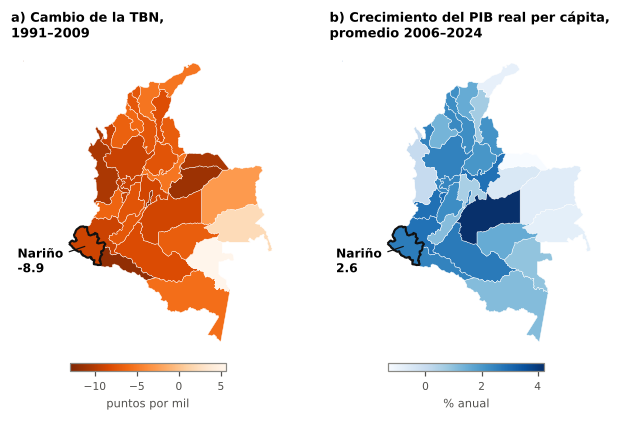

In [7]:
import geopandas as gpd
mapa = gpd.read_file(RAW / "mapa_departamentos.geojson")
mapa["dp"] = mapa.DPTO_CCDGO.astype(str).str.zfill(2)
mapa = mapa.merge(pd.DataFrame({"d_tbn": d_tbn, "g_media": est.groupby("dp").g.mean()}).reset_index(), on="dp", how="left")

fig, ejes = plt.subplots(1, 2, figsize=(7.4, 4.4), gridspec_kw={"wspace": 0.02})
for ax, col, cmap, titulo, unidad in [
        (ejes[0], "d_tbn", "Oranges_r", "a) Cambio de la TBN,\n1991–2009", "puntos por mil"),
        (ejes[1], "g_media", "Blues", "b) Crecimiento del PIB real per cápita,\npromedio 2006–2024", "% anual")]:
    mapa.plot(column=col, cmap=cmap, linewidth=0.3, edgecolor="white", ax=ax, legend=True,
              legend_kwds={"shrink": 0.5, "label": unidad, "orientation": "horizontal", "pad": 0.02})
    mapa[mapa.dp == "52"].boundary.plot(ax=ax, color="#111111", linewidth=1.4)
    x, y = mapa[mapa.dp == "52"].geometry.representative_point().iloc[0].coords[0]
    ax.annotate(f"Nariño\n{mapa.loc[mapa.dp == '52', col].iloc[0]:.1f}", (x, y), xytext=(x - 4.2, y - 1.6),
                fontsize=8, fontweight="bold", arrowprops=dict(arrowstyle="-", color="#111111", lw=0.8))
    ax.set_title(titulo, fontsize=8.5)
    ax.set_axis_off()
    cb = ax.get_figure().axes[-1]
    cb.tick_params(labelsize=7)
    cb.xaxis.label.set_size(7.5)
guardar_fig(fig, "Figura_1_mapas")

### Figura 2. Transición demográfica: Nariño frente a Colombia
Incluye las tasas globales de fecundidad (TGF) de estadísticas vitales publicadas en el boletín de nacimientos del DANE (2024) para 2014 y 2023, que contrastan con la estimación conciliada del DANE. Las líneas verticales punteadas marcan el empalme de series de población en 2018.

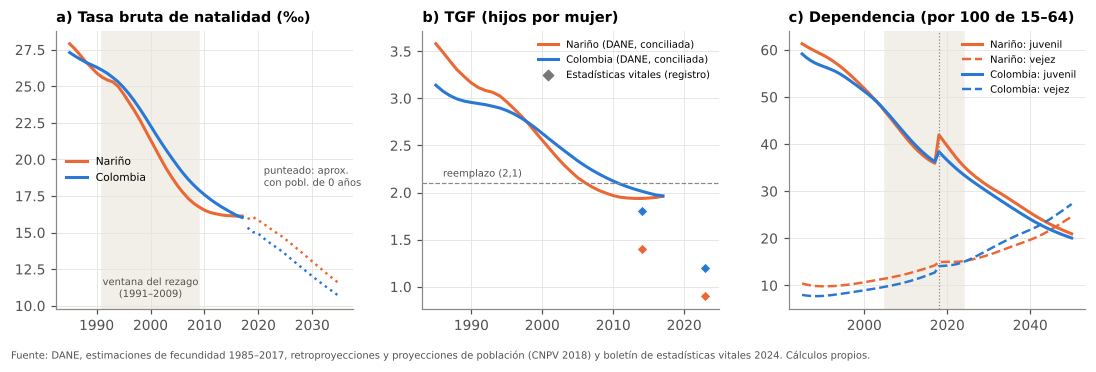

In [8]:
EEVV_TGF = pd.DataFrame({"anio": [2014, 2023, 2014, 2023], "dp": ["52", "52", "00", "00"],
                         "tgf_eevv": [1.4, 0.9, 1.8, 1.2]})   # DANE, Boletín técnico EEVV nacimientos 2024pr
serie = lambda dp, v: demo[demo.dp == dp].set_index("anio")[v]

fig, ejes = plt.subplots(1, 3, figsize=(10, 3.2))
ax = ejes[0]
for dp, c, et in [("52", C_NAR, "Nariño"), ("00", C_COL, "Colombia")]:
    ax.plot(serie(dp, "tbn").loc[1985:2017], color=c, label=et)
    ax.plot(serie(dp, "tbn_p0").loc[2018:2035], color=c, ls=":", lw=1.6)
ax.axvspan(1991, 2009, color="#f1efe8", zorder=0)
ax.text(2000, 10.6, "ventana del rezago\n(1991–2009)", ha="center", fontsize=6.5, color=C_TXT)
ax.set_title("a) Tasa bruta de natalidad (‰)")
ax.legend(loc="center left", fontsize=7)
ax.text(2021, 18.2, "punteado: aprox.\ncon pobl. de 0 años", fontsize=6.5, color=C_TXT)

ax = ejes[1]
for dp, c, et in [("52", C_NAR, "Nariño (DANE, conciliada)"), ("00", C_COL, "Colombia (DANE, conciliada)")]:
    ax.plot(serie(dp, "tgf").loc[1985:2017], color=c, label=et)
    e = EEVV_TGF[EEVV_TGF.dp == dp]
    ax.scatter(e.anio, e.tgf_eevv, color=c, marker="D", s=26, edgecolor="white", linewidth=0.8, zorder=3)
ax.scatter([], [], color="#777", marker="D", s=22, label="Estadísticas vitales (registro)")
ax.axhline(2.1, color="#8a8984", lw=0.8, ls="--")
ax.text(1986, 2.17, "reemplazo (2,1)", fontsize=6.5, color=C_TXT)
ax.set_title("b) TGF (hijos por mujer)")
ax.legend(loc="upper right", fontsize=6.5)

ax = ejes[2]
for dp, c, et in [("52", C_NAR, "Nariño"), ("00", C_COL, "Colombia")]:
    s = demo[demo.dp == dp].set_index("anio")
    ax.plot(s.dep_juv.loc[1985:2050], color=c, label=f"{et}: juvenil")
    ax.plot(s.dep_vej.loc[1985:2050], color=c, ls="--", lw=1.6, label=f"{et}: vejez")
ax.axvline(2018, color="#8a8984", lw=0.8, ls=":")
ax.axvspan(2005, 2024, color="#f1efe8", zorder=0)
ax.set_title("c) Dependencia (por 100 de 15–64)")
ax.legend(fontsize=6.5, loc="upper right", ncol=1)
fig.text(0.01, -0.03, "Fuente: DANE, estimaciones de fecundidad 1985–2017, retroproyecciones y proyecciones de población (CNPV 2018) "
         "y boletín de estadísticas vitales 2024. Cálculos propios.", fontsize=6.5, color=C_TXT)
fig.tight_layout()
guardar_fig(fig, "Figura_2_transicion")

### Figura 3. Pirámides poblacionales de Nariño: 2005, 2024 y 2035

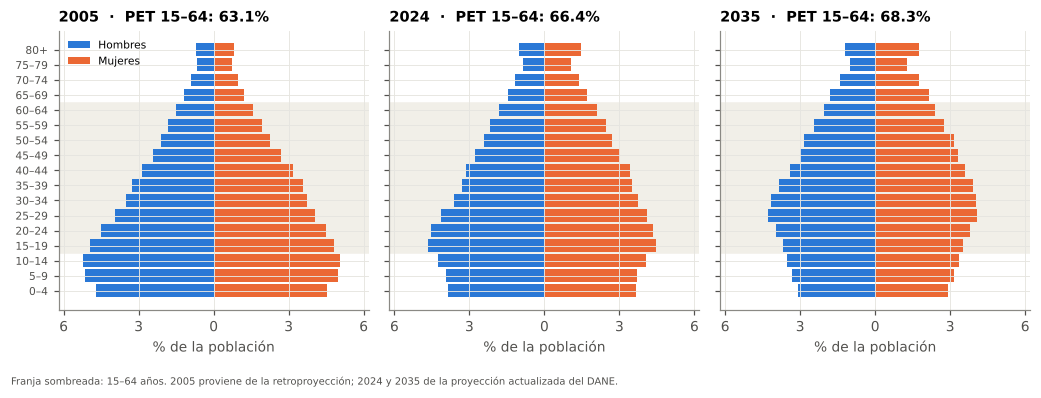

In [9]:
def piramide(dp, anio):
    p = pob[(pob.dp == dp) & (pob.anio == anio)].copy()
    p["grupo"] = np.minimum(p.edad // 5 * 5, 80)
    p = p.groupby(["grupo", "sexo"]).pob.sum().unstack()
    return 100 * p / p.values.sum()

fig, ejes = plt.subplots(1, 3, figsize=(9.5, 3.4), sharey=True)
etiquetas_g = [f"{g}–{g+4}" if g < 80 else "80+" for g in range(0, 85, 5)]
for ax, anio in zip(ejes, [2005, 2024, 2035]):
    p = piramide("52", anio)
    ax.barh(range(len(p)), -p["Hombres"], color=C_COL, height=0.85, label="Hombres")
    ax.barh(range(len(p)), p["Mujeres"], color=C_NAR, height=0.85, label="Mujeres")
    pet = demo[(demo.dp == "52") & (demo.anio == anio)].pet_sh.iloc[0]
    ax.set_title(f"{anio}  ·  PET 15–64: {pet:.1f}%")
    ax.axhspan(2.5, 12.5, color="#f1efe8", zorder=0)
    ax.set_xlim(-6.2, 6.2)
    ax.set_xticks([-6, -3, 0, 3, 6], ["6", "3", "0", "3", "6"])
    ax.set_xlabel("% de la población")
ejes[0].set_yticks(range(len(etiquetas_g)), etiquetas_g, fontsize=7)
ejes[0].legend(loc="upper left", fontsize=7)
fig.text(0.01, -0.04, "Franja sombreada: 15–64 años. 2005 proviene de la retroproyección; 2024 y 2035 de la proyección actualizada del DANE.",
         fontsize=6.5, color=C_TXT)
fig.tight_layout()
guardar_fig(fig, "Figura_3_piramides")

### Figura 4. Mercado laboral de Nariño frente al agregado de 23 departamentos

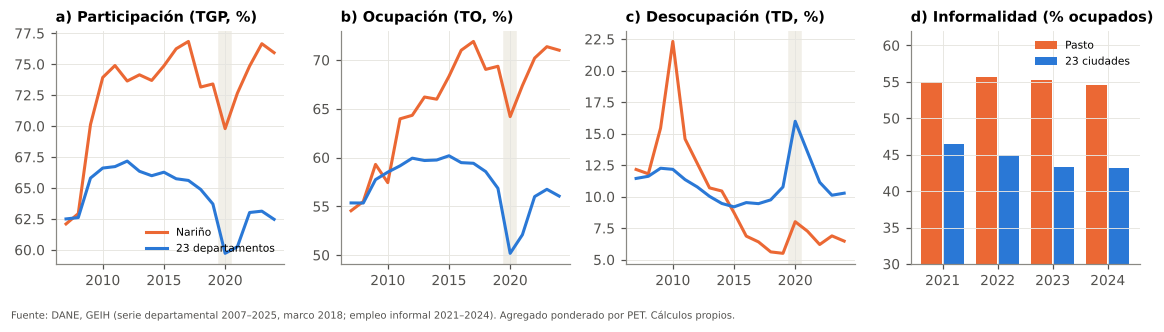

In [10]:
agg = geih.groupby("anio")[["pet_miles", "ft_miles", "ocu_miles"]].sum()
agg = pd.DataFrame({"tgp": 100 * agg.ft_miles / agg.pet_miles, "to": 100 * agg.ocu_miles / agg.pet_miles,
                    "td": 100 * (agg.ft_miles - agg.ocu_miles) / agg.ft_miles})
nar_l = geih[geih.dp == "52"].set_index("anio")
fig, ejes = plt.subplots(1, 4, figsize=(10.5, 2.8))
for ax, v, t in zip(ejes[:3], ["tgp", "to", "td"], ["a) Participación (TGP, %)", "b) Ocupación (TO, %)", "c) Desocupación (TD, %)"]):
    ax.plot(nar_l[v].loc[:2024], color=C_NAR, label="Nariño")
    ax.plot(agg[v].loc[:2024], color=C_COL, label="23 departamentos")
    ax.axvspan(2019.5, 2020.5, color="#f1efe8", zorder=0)
    ax.set_title(t)
ejes[0].legend(fontsize=7, loc="lower right")
ax = ejes[3]
inf_p = informalidad[informalidad.dp == "52"].set_index("anio").inf
inf_23 = informalidad[informalidad.dp == "23C"].set_index("anio").inf
ax.bar(np.array(inf_p.index) - 0.2, inf_p.values, width=0.38, color=C_NAR, label="Pasto")
ax.bar(np.array(inf_23.index) + 0.2, inf_23.values, width=0.38, color=C_COL, label="23 ciudades")
ax.set_ylim(30, 62)
ax.set_title("d) Informalidad (% ocupados)")
ax.legend(fontsize=7, loc="upper right")
fig.text(0.01, -0.05, "Fuente: DANE, GEIH (serie departamental 2007–2025, marco 2018; empleo informal 2021–2024). Agregado ponderado por PET. Cálculos propios.",
         fontsize=6.5, color=C_TXT)
fig.tight_layout()
guardar_fig(fig, "Figura_4_mercado_laboral")

### Figura 5. Caída de la natalidad y crecimiento: corte transversal de departamentos

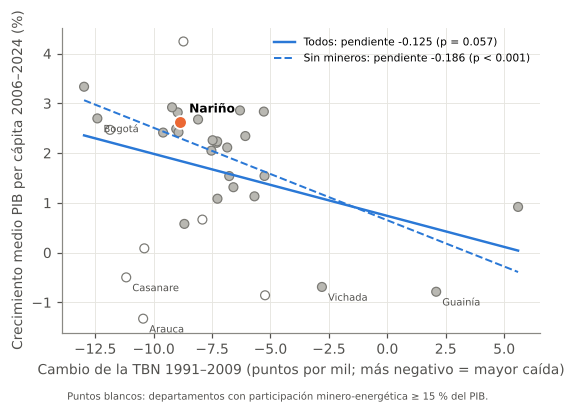

In [11]:
xs = pd.DataFrame({"d_tbn": d_tbn, "g": est.groupby("dp").g.mean(), "minas": est.groupby("dp").minas_sh.mean()}).dropna()
pend = sm.OLS(xs.g, sm.add_constant(xs.d_tbn)).fit()
pend_sm = sm.OLS(xs[xs.minas < 15].g, sm.add_constant(xs[xs.minas < 15].d_tbn)).fit()
fig, ax = plt.subplots(figsize=(5.6, 3.6))
otros = xs.drop("52")
ax.scatter(otros.d_tbn, otros.g, s=34, color=np.where(otros.minas >= 15, "white", C_GRIS),
           edgecolor="#7b7a75", linewidth=0.8, zorder=2)
ax.scatter(xs.loc["52", "d_tbn"], xs.loc["52", "g"], s=70, color=C_NAR, edgecolor="white", linewidth=1.2, zorder=3)
ax.annotate("Nariño", (xs.loc["52", "d_tbn"], xs.loc["52", "g"]), xytext=(6, 6), textcoords="offset points",
            fontsize=8, fontweight="bold")
xx = np.linspace(xs.d_tbn.min(), xs.d_tbn.max(), 50)
ax.plot(xx, pend.params.iloc[0] + pend.params.iloc[1] * xx, color=C_COL, lw=1.6,
        label=f"Todos: pendiente {pend.params.iloc[1]:.3f} (p = {pend.pvalues.iloc[1]:.3f})")
ax.plot(xx, pend_sm.params.iloc[0] + pend_sm.params.iloc[1] * xx, color=C_COL, lw=1.3, ls="--",
        label=f"Sin mineros: pendiente {pend_sm.params.iloc[1]:.3f} (p {'< 0.001' if pend_sm.pvalues.iloc[1] < 0.001 else '= ' + format(pend_sm.pvalues.iloc[1], '.3f')})")
for dp in xs.index:
    if dp in ("11", "85", "81", "99", "94") or abs(xs.loc[dp, "g"] - xs.g.mean()) > 2.2 * xs.g.std():
        ax.annotate(NOMBRE[dp].split(",")[0].replace("Archipiélago de ", ""), (xs.loc[dp, "d_tbn"], xs.loc[dp, "g"]),
                    xytext=(4, -9), textcoords="offset points", fontsize=6.5, color=C_TXT)
ax.set_xlabel("Cambio de la TBN 1991–2009 (puntos por mil; más negativo = mayor caída)")
ax.set_ylabel("Crecimiento medio PIB per cápita 2006–2024 (%)")
ax.legend(fontsize=7, loc="upper right")
ax.text(0.01, -0.22, "Puntos blancos: departamentos con participación minero-energética ≥ 15 % del PIB.", transform=ax.transAxes,
        fontsize=6.5, color=C_TXT)
guardar_fig(fig, "Figura_5_dispersion")

## 5. Panel departamental con efectos fijos (objetivo 2; H1, H2 y H3)
$$g_{it}=\alpha_i+\lambda_t+\beta_1\,TBN_{i,t-15}+\beta_2\,(TBN_{i,t-15}\times Nariño_i)+\gamma' X_{i,t-1}+\varepsilon_{it}$$
Efectos fijos de departamento ($\alpha_i$) y de año ($\lambda_t$); errores estándar agrupados por departamento. H1 espera $\beta_1<0$ (menos natalidad rezagada → más crecimiento) y $\beta_2>0$ (efecto más débil en Nariño). H3 sustituye la interacción con Nariño por una interacción con la informalidad (centrada).

In [12]:
est["tbn_l15_x_nar"] = est.tbn_l15 * est.narino
inf_c = est.inf_2124 - est.groupby("dp").inf_2124.first().mean()
est["tbn_l15_x_inf"] = est.tbn_l15 * inf_c
CONTROLES = ["agro_sh_l1", "minas_sh_l1"]

def estimar(df, y, x, efectos_tiempo=True):
    """Panel con efectos fijos de departamento (y de año) y errores agrupados por departamento."""
    d = df.dropna(subset=[y] + x).set_index(["dp", "anio"])
    mod = PanelOLS(d[y], d[x], entity_effects=True, time_effects=efectos_tiempo, drop_absorbed=True)
    return mod.fit(cov_type="clustered", cluster_entity=True)

lab = est[est.anio >= 2007]
MODELOS = {
    "(1) g": estimar(est, "g", ["tbn_l15"]),
    "(2) g": estimar(est, "g", ["tbn_l15"] + CONTROLES),
    "(3) g": estimar(est, "g", ["tbn_l15", "tbn_l15_x_nar"] + CONTROLES),
    "(4) g · H3": estimar(est.dropna(subset=["inf_2124"]), "g", ["tbn_l15", "tbn_l15_x_inf"] + CONTROLES),
    "(5) g · PET": estimar(est, "g", ["d_ln_pet_sh"] + CONTROLES),
    "(6) TGP · H2": estimar(lab, "tgp", ["tbn_l15", "tbn_l15_x_nar"]),
    "(7) TO": estimar(lab, "to", ["tbn_l15", "tbn_l15_x_nar"]),
}
ETIQUETAS = {"tbn_l15": "TBN (t−15)", "tbn_l15_x_nar": "TBN (t−15) × Nariño", "tbn_l15_x_inf": "TBN (t−15) × informalidad",
             "d_ln_pet_sh": "Δln PET 15–64 (%)", "agro_sh_l1": "Part. agropecuaria (t−1)", "minas_sh_l1": "Part. minero-energética (t−1)"}

def estrellas(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

def tabla_modelos(modelos):
    filas = {}
    for nombre, r in modelos.items():
        col = {}
        for v, et in ETIQUETAS.items():
            if v in r.params.index:
                col[et] = f"{r.params[v]:.3f}{estrellas(r.pvalues[v])}"
                col[et + " "] = f"({r.std_errors[v]:.3f})"
        if "tbn_l15_x_nar" in r.params.index:
            b = r.params["tbn_l15"] + r.params["tbn_l15_x_nar"]
            V = r.cov.loc[["tbn_l15", "tbn_l15_x_nar"], ["tbn_l15", "tbn_l15_x_nar"]].values.sum()
            col["Efecto total en Nariño (β1+β2)"] = f"{b:.3f}{estrellas(2 * stats.norm.sf(abs(b / np.sqrt(V))))}"
            col["Efecto total en Nariño (β1+β2) "] = f"({np.sqrt(V):.3f})"
        col["Observaciones"] = f"{int(r.nobs)}"
        col["Departamentos"] = f"{int(r.entity_info['total'])}"
        col["Años"] = f"{int(r.time_info['total'])}"
        col["R² within"] = f"{r.rsquared:.3f}"
        filas[nombre] = col
    t = pd.DataFrame(filas)
    orden = [i for i in t.index if not i.startswith(("Observ", "Depart", "Años", "R²"))] + ["Observaciones", "Departamentos", "Años", "R² within"]
    return t.loc[orden].fillna("")

tabla6 = tabla_modelos(MODELOS)
tabla6.loc["EF departamento y año"] = "Sí"

# (8) Diferencias largas entre departamentos: crecimiento medio 2006–2024 vs cambio de la TBN 1991–2009
largo = pd.DataFrame({"g": est.groupby("dp").g.mean(), "d_tbn": d_tbn, "agro": est.groupby("dp").agro_sh.mean(),
                      "minas": est.groupby("dp").minas_sh.mean()}).dropna()
largo["nar"] = (largo.index == "52").astype(float)
r_largo = sm.OLS(largo.g, sm.add_constant(largo[["d_tbn", "agro", "minas"]])).fit(cov_type="HC3")
# Robustez: control de convergencia (logaritmo del PIB per cápita inicial, 2005)
largo["ln_y2005"] = np.log(panel[panel.anio == 2005].set_index("dp").ypc)
r_largo_conv = sm.OLS(largo.g, sm.add_constant(largo[["d_tbn", "agro", "minas", "ln_y2005"]])).fit(cov_type="HC3")
print(f"Largo plazo con convergencia: β(ΔTBN) = {r_largo_conv.params['d_tbn']:.3f} (p = {r_largo_conv.pvalues['d_tbn']:.3f}); "
      f"β(ln y2005) = {r_largo_conv.params['ln_y2005']:.3f} (p = {r_largo_conv.pvalues['ln_y2005']:.3f})")
resid_nar = r_largo.resid["52"]
pct_resid_nar = (r_largo.resid < resid_nar).mean() * 100
col8 = {"Cambio TBN 1991–2009 (entre dptos.)": f"{r_largo.params['d_tbn']:.3f}{estrellas(r_largo.pvalues['d_tbn'])}",
        "Cambio TBN 1991–2009 (entre dptos.) ": f"({r_largo.bse['d_tbn']:.3f})",
        "Part. agropecuaria (t−1)": f"{r_largo.params['agro']:.3f}{estrellas(r_largo.pvalues['agro'])}",
        "Part. agropecuaria (t−1) ": f"({r_largo.bse['agro']:.3f})",
        "Part. minero-energética (t−1)": f"{r_largo.params['minas']:.3f}{estrellas(r_largo.pvalues['minas'])}",
        "Part. minero-energética (t−1) ": f"({r_largo.bse['minas']:.3f})",
        "Observaciones": f"{int(r_largo.nobs)}", "Departamentos": f"{int(r_largo.nobs)}", "Años": "promedio",
        "R² within": f"{r_largo.rsquared:.3f}", "EF departamento y año": "No (corte transversal, EE HC3)"}
tabla6 = pd.concat([tabla6, pd.Series(col8, name="(8) g · largo plazo")], axis=1)
orden = [i for i in tabla6.index if i not in ("Observaciones", "Departamentos", "Años", "R² within", "EF departamento y año")]
orden = [i for i in orden if not i.startswith("Cambio TBN")] + ["Cambio TBN 1991–2009 (entre dptos.)", "Cambio TBN 1991–2009 (entre dptos.) "]
tabla6 = tabla6.loc[orden + ["Observaciones", "Departamentos", "Años", "R² within", "EF departamento y año"]].fillna("")
guardar_tabla(tabla6, "Tabla_6_panel")
display(tabla6)
print("Errores estándar agrupados por departamento entre paréntesis. *** p<0.01; ** p<0.05; * p<0.10.")

Largo plazo con convergencia: β(ΔTBN) = -0.187 (p = 0.002); β(ln y2005) = -0.861 (p = 0.046)


,(1) g,(2) g,(3) g,(4) g · H3,(5) g · PET,(6) TGP · H2,(7) TO,(8) g · largo plazo
TBN (t−15),0.059,0.065,0.069,-0.291,,0.973,0.838,
TBN (t−15),(0.074),(0.077),(0.079),(0.405),,(0.965),(1.021),
Part. agropecuaria (t−1),,0.115,0.113,-0.172,0.113,,,-0.062**
Part. agropecuaria (t−1),,(0.098),(0.098),(0.194),(0.096),,,(0.026)
Part. minero-energética (t−1),,-0.068*,-0.069*,-0.166***,-0.071*,,,-0.039*
Part. minero-energética (t−1),,(0.036),(0.036),(0.060),(0.038),,,(0.023)
TBN (t−15) × Nariño,,,-0.186**,,,-1.416***,-2.105***,
TBN (t−15) × Nariño,,,(0.093),,,(0.200),(0.217),
Efecto total en Nariño (β1+β2),,,-0.116*,,,-0.443,-1.267,
Efecto total en Nariño (β1+β2),,,(0.060),,,(0.823),(0.857),


Errores estándar agrupados por departamento entre paréntesis. *** p<0.01; ** p<0.05; * p<0.10.


## 5b. Panel dinámico: System GMM (Arellano-Bover / Blundell-Bond)
El panel con efectos fijos trata cada año como independiente. El modelo dinámico (en la línea de Cruz y Ahmed, 2018) incorpora la persistencia del crecimiento:
$$g_{it}=\rho\,g_{i,t-1}+\beta\,TBN_{i,t-15}+\gamma' X_{i,t-1}+\eta_i+\varepsilon_{it}$$
Con efectos fijos, $g_{i,t-1}$ está correlacionado con el error transformado (sesgo de Nickell, 1981), por lo que se estima por **System GMM** (Blundell y Bond, 1998):
ecuaciones en diferencias instrumentadas con niveles rezagados (t−2, t−3) y ecuaciones en niveles instrumentadas con la diferencia rezagada.
* Instrumentos **colapsados** (Roodman, 2009) para que su número no supere los 33 departamentos.
* Todas las variables se expresan como desviación de la media anual, lo que absorbe los choques comunes (equivale a efectos de año).
* $TBN_{t-15}$ y los controles rezagados se tratan como predeterminados (instrumentos tipo IV). Efecto de largo plazo: $\beta/(1-\rho)$.
* Diagnósticos: Hansen J (validez conjunta de los instrumentos), AR(1)/AR(2) de Arellano-Bond sobre los residuos en diferencias y la regla de Bond: $\hat\rho$ debe quedar entre MCO agrupado (sesgo hacia arriba) y efectos fijos (sesgo hacia abajo).
* Contraste: la forma en niveles, $\ln y_{it}=\rho\ln y_{i,t-1}+\dots$, mide convergencia condicional ($\rho<1$).
* Se reportan coeficientes de un paso con errores robustos por departamento; la fila de dos pasos sirve de contraste.

In [13]:
def sys_gmm(df, y, xs, id_="dp", t_="anio", lags=(2, 3), demean_t=True):
    """System GMM con instrumentos colapsados.
    df: panel largo; y: variable dependiente en niveles; xs: regresores predeterminados (instrumentos tipo IV).
    Devuelve coeficientes de un paso (EE robustos), coeficientes de dos pasos, Hansen J y pruebas AR(1)/AR(2)."""
    d = df[[id_, t_, y] + list(xs)].dropna().sort_values([id_, t_]).copy()
    if demean_t:                                   # desviación de la media de cada año
        for c in [y] + list(xs):
            d[c] = d[c] - d.groupby(t_)[c].transform("mean")
    nombres = ["L1." + y] + list(xs) + ["constante"]
    k = len(nombres)
    bloques = []
    for i, g in d.groupby(id_):
        g = g.set_index(t_)
        Y, X = g[y], g[list(xs)]
        Xd, yd, Zd, Xl, yl, Zl = [], [], [], [], [], []
        for t in g.index:
            if (t - 1) not in g.index or (t - 2) not in g.index:
                continue
            # Ecuación en diferencias: Δy_t = ρΔy_{t-1} + Δx_t'β ; instrumentos y_{t-2}, y_{t-3} (colapsados) y Δx_t
            Zd.append([Y[t - l] if (t - l) in g.index else 0.0 for l in range(lags[0], lags[1] + 1)] + list(X.loc[t] - X.loc[t - 1]))
            Xd.append([Y[t - 1] - Y[t - 2]] + list(X.loc[t] - X.loc[t - 1]) + [0.0]); yd.append(Y[t] - Y[t - 1])
            # Ecuación en niveles: y_t = ρy_{t-1} + x_t'β + c ; instrumentos Δy_{t-1}, x_t y constante
            Zl.append([Y[t - 1] - Y[t - 2]] + list(X.loc[t]) + [1.0])
            Xl.append([Y[t - 1]] + list(X.loc[t]) + [1.0]); yl.append(Y[t])
        if not Xd:
            continue
        Zd, Zl = np.array(Zd), np.array(Zl)
        nd, nl = len(Zd), len(Zl)
        Z = np.zeros((nd + nl, Zd.shape[1] + Zl.shape[1]))
        Z[:nd, :Zd.shape[1]], Z[nd:, Zd.shape[1]:] = Zd, Zl
        H = np.zeros((nd + nl, nd + nl))                      # matriz de ponderación del primer paso
        H[:nd, :nd] = 2 * np.eye(nd) - np.eye(nd, k=1) - np.eye(nd, k=-1)
        H[nd:, nd:] = np.eye(nl)
        bloques.append(dict(X=np.vstack([Xd, Xl]), y=np.r_[yd, yl], Z=Z, H=H, nd=nd))
    ZX = sum(b["Z"].T @ b["X"] for b in bloques)
    Zy = sum(b["Z"].T @ b["y"] for b in bloques)
    def gmm(W):
        A = np.linalg.pinv(ZX.T @ W @ ZX)
        return A @ ZX.T @ W @ Zy, A
    W1 = np.linalg.pinv(sum(b["Z"].T @ b["H"] @ b["Z"] for b in bloques))
    b1, A1 = gmm(W1)
    S = sum(b["Z"].T @ np.outer(b["y"] - b["X"] @ b1, b["y"] - b["X"] @ b1) @ b["Z"] for b in bloques)
    V1 = A1 @ ZX.T @ W1 @ S @ W1 @ ZX @ A1                  # varianza robusta del primer paso
    W2 = np.linalg.pinv(S)
    b2, _ = gmm(W2)
    m2 = sum(b["Z"].T @ (b["y"] - b["X"] @ b2) for b in bloques)
    J, L = float(m2 @ W2 @ m2), bloques[0]["Z"].shape[1]
    def prueba_ar(m):                                      # Arellano-Bond AR(m), residuos en diferencias
        w = []
        for b in bloques:
            e = (b["y"] - b["X"] @ b1)[:b["nd"]]
            w.append(np.sum(e[m:] * e[:-m]) if len(e) > m else 0.0)
        w = np.array(w)
        z = w.sum() / np.sqrt((w ** 2).sum())
        return z, 2 * stats.norm.sf(abs(z))
    se = np.sqrt(np.diag(V1))
    tabla = pd.DataFrame({"coef": b1, "ee": se, "p": 2 * stats.norm.sf(np.abs(b1 / se)), "coef_2p": b2}, index=nombres)
    return dict(tabla=tabla, V=pd.DataFrame(V1, index=nombres, columns=nombres), J=J, gl_J=L - k,
                p_J=stats.chi2.sf(J, L - k), ar1=prueba_ar(1), ar2=prueba_ar(2), n_inst=L, N=len(bloques),
                nobs=sum(b["nd"] for b in bloques))

def cotas_rho(df, y, xs, id_="dp", t_="anio"):
    """Regla de Bond (2002): ρ de MCO agrupado (cota superior) y de efectos fijos (cota inferior), con las mismas
    variables en desviación de la media anual que usa sys_gmm."""
    d = df[[id_, t_, y] + list(xs)].dropna().sort_values([id_, t_]).copy()
    d["L1"] = d.groupby(id_)[y].shift(1)
    d = d.dropna()
    for c in [y, "L1"] + list(xs):
        d[c] = d[c] - d.groupby(t_)[c].transform("mean")
    ols = sm.OLS(d[y], sm.add_constant(d[["L1"] + list(xs)])).fit()
    fe = PanelOLS(d.set_index([id_, t_])[y], d.set_index([id_, t_])[["L1"] + list(xs)], entity_effects=True).fit()
    return ols.params["L1"], fe.params["L1"]

# (a) Panel anual 2006–2024: crecimiento g (p.p.) con su propio rezago
dg = panel[(panel.anio >= 2005) & (panel.anio <= ANIO_FIN)].copy()
dg["lny"] = 100 * np.log(dg.ypc)
dg["tbn_x_nar"] = dg.tbn_l15 * (dg.dp == "52")
dgg = dg.dropna(subset=["g"])

# (b) Periodos de cuatro años no superpuestos (2006–09, 10–13, 14–17, 18–21, 22–24): atenúa el ciclo de corto plazo
CORTES = [2005, 2009, 2013, 2017, 2021, 2024]
filas = []
for dp_, g_ in dg.groupby("dp"):
    g_ = g_.set_index("anio")
    for p_, (a_, b_) in enumerate(zip(CORTES[:-1], CORTES[1:]), start=1):
        sub = g_.loc[a_ + 1:b_]
        filas.append(dict(dp=dp_, per=p_, g=sub.g.mean(), tbn_l15=sub.tbn_l15.mean(), dep_juv=sub.dep_juv.mean(),
                          agro_sh_l1=sub.agro_sh_l1.mean(), minas_sh_l1=sub.minas_sh_l1.mean()))
dq = pd.DataFrame(filas).sort_values(["dp", "per"])

GMM = {
    "(9) GMM anual": sys_gmm(dgg, "g", ["tbn_l15"] + CONTROLES),
    "(10) GMM anual × Nariño": sys_gmm(dgg, "g", ["tbn_l15", "tbn_x_nar"] + CONTROLES),
    "(11) GMM anual · dependencia": sys_gmm(dgg, "g", ["dep_juv"] + CONTROLES),
    "(12) GMM 4 años": sys_gmm(dq, "g", ["tbn_l15"] + CONTROLES, t_="per"),
    "(13) GMM niveles · convergencia": sys_gmm(dg, "lny", ["tbn_l15"] + CONTROLES),
}
COTAS = {"(9) GMM anual": cotas_rho(dgg, "g", ["tbn_l15"] + CONTROLES),
         "(12) GMM 4 años": cotas_rho(dq, "g", ["tbn_l15"] + CONTROLES, t_="per"),
         "(13) GMM niveles · convergencia": cotas_rho(dg, "lny", ["tbn_l15"] + CONTROLES)}
ETQ_GMM = {"L1.g": "g (t−1) · ρ", "L1.lny": "ln y (t−1) · ρ", "tbn_l15": "TBN (t−15)", "tbn_x_nar": "TBN (t−15) × Nariño", "dep_juv": "Dependencia juvenil",
           "agro_sh_l1": "Part. agropecuaria (t−1)", "minas_sh_l1": "Part. minero-energética (t−1)"}
cols = {}
for nombre, r in GMM.items():
    t_ = r["tabla"]
    col = {}
    for v, et in ETQ_GMM.items():
        if v in t_.index:
            col[et] = f"{t_.coef[v]:.3f}{estrellas(t_.p[v])}"
            col[et + " "] = f"({t_.ee[v]:.3f})"
    col["Coef. demográfico, dos pasos"] = f"{t_.coef_2p.iloc[1]:.3f}"
    col["Efecto de largo plazo β/(1−ρ)"] = f"{t_.coef.iloc[1] / (1 - t_.coef.iloc[0]):.3f}" if t_.coef.iloc[0] < 1 else "no definido (ρ ≥ 1)"
    if nombre in COTAS:
        col["ρ MCO / ρ EF (cotas)"] = f"{COTAS[nombre][0]:.3f} / {COTAS[nombre][1]:.3f}"
    col["Instrumentos / departamentos"] = f"{r['n_inst']} / {r['N']}"
    col["Hansen J (p)"] = f"{r['J']:.2f} ({r['p_J']:.2f})"
    col["AR(1) (p)"] = f"{r['ar1'][0]:.2f} ({r['ar1'][1]:.2f})"
    col["AR(2) (p)"] = f"{r['ar2'][0]:.2f} ({r['ar2'][1]:.2f})"
    col["Observaciones (dif.)"] = f"{r['nobs']}"
    cols[nombre] = col
tabla6c = pd.DataFrame(cols)
orden = [i for i in tabla6c.index if i.startswith(tuple(ETQ_GMM.values()))]
orden += [i for i in tabla6c.index if i not in orden]
tabla6c = tabla6c.loc[orden].fillna("")
guardar_tabla(tabla6c, "Tabla_6c_gmm")
display(tabla6c)
print("Coeficientes de un paso; errores robustos por departamento entre paréntesis. Variables en desviación de la media anual.")

g9 = GMM["(9) GMM anual"]["tabla"]
g13 = GMM["(13) GMM niveles · convergencia"]["tabla"]
GMM_CLAVE = {"gmm_rho": g9.coef["L1.g"], "gmm_rho_ee": g9.ee["L1.g"], "gmm_tbn": g9.coef["tbn_l15"],
             "gmm_tbn_ee": g9.ee["tbn_l15"], "gmm_tbn_p": g9.p["tbn_l15"], "gmm_tbn_2p": g9.coef_2p["tbn_l15"],
             "gmm_lp": g9.coef["tbn_l15"] / (1 - g9.coef["L1.g"]),
             "gmm_J_p": GMM["(9) GMM anual"]["p_J"], "gmm_ar1_p": GMM["(9) GMM anual"]["ar1"][1],
             "gmm_ar2_p": GMM["(9) GMM anual"]["ar2"][1], "gmm_ninst": GMM["(9) GMM anual"]["n_inst"],
             "gmm_rho_ols": COTAS["(9) GMM anual"][0], "gmm_rho_fe": COTAS["(9) GMM anual"][1],
             "gmm_nar_inter": GMM["(10) GMM anual × Nariño"]["tabla"].coef["tbn_x_nar"],
             "gmm_nar_inter_p": GMM["(10) GMM anual × Nariño"]["tabla"].p["tbn_x_nar"],
             "gmm_dep": GMM["(11) GMM anual · dependencia"]["tabla"].coef["dep_juv"],
             "gmm_dep_p": GMM["(11) GMM anual · dependencia"]["tabla"].p["dep_juv"],
             "gmm4_rho": GMM["(12) GMM 4 años"]["tabla"].coef["L1.g"], "gmm4_tbn": GMM["(12) GMM 4 años"]["tabla"].coef["tbn_l15"],
             "gmm4_tbn_p": GMM["(12) GMM 4 años"]["tabla"].p["tbn_l15"], "gmm4_J_p": GMM["(12) GMM 4 años"]["p_J"],
             "gmm4_ar2_p": GMM["(12) GMM 4 años"]["ar2"][1],
             "gmm4_rho_ols": COTAS["(12) GMM 4 años"][0], "gmm4_rho_fe": COTAS["(12) GMM 4 años"][1],
             "gmmniv_rho": g13.coef["L1.lny"], "gmmniv_rho_ols": COTAS["(13) GMM niveles · convergencia"][0],
             "gmmniv_rho_fe": COTAS["(13) GMM niveles · convergencia"][1], "gmmniv_tbn": g13.coef["tbn_l15"],
             "gmmniv_tbn_p": g13.p["tbn_l15"],
             "gmm_minas": g9.coef["minas_sh_l1"], "gmm_minas_p": g9.p["minas_sh_l1"]}
print(f"System GMM (9): β(TBN t−15) = {GMM_CLAVE['gmm_tbn']:.3f} (p = {GMM_CLAVE['gmm_tbn_p']:.3f}); ρ = {GMM_CLAVE['gmm_rho']:.3f} "
      f"entre las cotas MCO {GMM_CLAVE['gmm_rho_ols']:.3f} y EF {GMM_CLAVE['gmm_rho_fe']:.3f}; largo plazo = {GMM_CLAVE['gmm_lp']:.3f}.")

,(9) GMM anual,(10) GMM anual × Nariño,(11) GMM anual · dependencia,(12) GMM 4 años,(13) GMM niveles · convergencia
g (t−1) · ρ,0.164,0.165,0.162,0.245**,
g (t−1) · ρ,(0.140),(0.140),(0.141),(0.106),
TBN (t−15),-0.060***,-0.060***,,-0.049**,0.324
TBN (t−15),(0.022),(0.022),,(0.023),(0.245)
Part. agropecuaria (t−1),-0.027,-0.028,-0.024,-0.017,0.215
Part. agropecuaria (t−1),(0.024),(0.025),(0.025),(0.029),(0.163)
Part. minero-energética (t−1),-0.031**,-0.030**,-0.031**,-0.059***,-0.139***
Part. minero-energética (t−1),(0.015),(0.015),(0.015),(0.004),(0.053)
TBN (t−15) × Nariño,,0.010,,,
TBN (t−15) × Nariño,,(0.011),,,


Coeficientes de un paso; errores robustos por departamento entre paréntesis. Variables en desviación de la media anual.
System GMM (9): β(TBN t−15) = -0.060 (p = 0.005); ρ = 0.164 entre las cotas MCO 0.220 y EF 0.183; largo plazo = -0.072.


## 6. Diagnósticos y robustez
### 6.1 Diagnósticos del modelo base (columna 2)
* **Poolabilidad (F)**: ¿son necesarios los efectos fijos?
* **Pesaran CD**: dependencia transversal de los residuos.
* **Wooldridge**: autocorrelación de primer orden en panel.
* **Wald modificado**: heterocedasticidad entre departamentos.
* **Bootstrap salvaje por conglomerados** (Rademacher, 1999 réplicas, hipótesis nula impuesta): inferencia robusta con 33 conglomerados.
* **Inferencia por aleatorización (placebo)**: la interacción con Nariño se estima con un solo departamento, así que su error estándar agrupado no es confiable; se compara con las interacciones placebo de los 33 departamentos.

In [14]:
base = MODELOS["(2) g"]
d_b = est.dropna(subset=["g", "tbn_l15"] + CONTROLES)

def resid_matriz(res, df):
    e = res.resids.reset_index()
    e.columns = ["dp", "anio", "e"]
    return e.pivot(index="anio", columns="dp", values="e")

def pesaran_cd(E):
    T, N = E.shape
    R = E.corr().values
    s = R[np.triu_indices(N, 1)].sum()
    cd = np.sqrt(2 * T / (N * (N - 1))) * s
    return cd, 2 * stats.norm.sf(abs(cd)), R[np.triu_indices(N, 1)].mean()

def wooldridge_ar1(df, y, x):
    d = df.sort_values(["dp", "anio"]).copy()
    for v in [y] + x:
        d["D_" + v] = d.groupby("dp")[v].diff()
    d = d.dropna(subset=["D_" + v for v in [y] + x])
    X = pd.get_dummies(d.anio, prefix="a", drop_first=True, dtype=float)
    X = pd.concat([d[["D_" + v for v in x]], X], axis=1)
    r = sm.OLS(d["D_" + y], sm.add_constant(X)).fit()
    d["u"] = r.resid
    d["u_l"] = d.groupby("dp").u.shift(1)
    d2 = d.dropna(subset=["u_l"])
    r2 = sm.OLS(d2.u, d2.u_l).fit(cov_type="cluster", cov_kwds={"groups": d2.dp.astype("category").cat.codes})
    F = ((r2.params.iloc[0] + 0.5) / r2.bse.iloc[0]) ** 2
    return F, stats.f.sf(F, 1, d2.dp.nunique() - 1), r2.params.iloc[0]

def wald_modificado(E):
    sig_i = (E ** 2).mean()
    T = E.notna().sum()
    V = ((E ** 2 - sig_i) ** 2).sum() / (T * (T - 1))
    W = (((sig_i - (E ** 2).stack().mean()) ** 2) / V).sum()
    return W, stats.chi2.sf(W, E.shape[1])

def doble_demean(df, cols):
    """Transformación within de dos vías (panel balanceado)."""
    out = df[cols].copy()
    for c in cols:
        out[c] = df[c] - df.groupby("dp")[c].transform("mean") - df.groupby("anio")[c].transform("mean") + df[c].mean()
    return out

def t_cluster(y, X, g):
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    u = y - X @ b
    XtXi = np.linalg.inv(X.T @ X)
    meat = np.zeros((X.shape[1], X.shape[1]))
    for k in np.unique(g):
        s = X[g == k].T @ u[g == k]
        meat += np.outer(s, s)
    G, n, K = len(np.unique(g)), len(y), X.shape[1]
    V = XtXi @ meat @ XtXi * G / (G - 1) * (n - 1) / (n - K)
    return b, b / np.sqrt(np.diag(V))

def wild_cluster_bootstrap(df, y, x, prueba="tbn_l15", B=1999):
    d = doble_demean(df, [y] + x)
    Y, X = d[y].values, d[x].values
    g = df.dp.values
    j = x.index(prueba)
    _, t_obs = t_cluster(Y, X, g)
    Xr = np.delete(X, j, axis=1)
    br = np.linalg.lstsq(Xr, Y, rcond=None)[0]
    ajuste, u_r = Xr @ br, Y - Xr @ br
    grupos = np.unique(g)
    idx = np.searchsorted(grupos, g)
    t_b = np.empty(B)
    for b in range(B):
        w = rng.choice([-1.0, 1.0], size=len(grupos))[idx]
        _, tb = t_cluster(ajuste + u_r * w, X, g)
        t_b[b] = tb[j]
    return t_obs[j], np.mean(np.abs(t_b) >= abs(t_obs[j]))

# Interacciones placebo: TBN(t−15) × 1[departamento = d] para cada departamento
placebo = {}
for dp in sorted(est.dp.unique()):
    tmp = est.assign(inter=est.tbn_l15 * (est.dp == dp))
    placebo[dp] = estimar(tmp, "g", ["tbn_l15", "inter"] + CONTROLES).params["inter"]
placebo = pd.Series(placebo).sort_values()
b2_nar = placebo["52"]
p_ri = np.mean(np.abs(placebo.values) >= abs(b2_nar))

E = resid_matriz(base, d_b)
cd, p_cd, rho = pesaran_cd(E)
F_w, p_w, rho_ar = wooldridge_ar1(d_b, "g", ["tbn_l15"] + CONTROLES)
W_h, p_h = wald_modificado(E)
t_wb, p_wb = wild_cluster_bootstrap(d_b, "g", ["tbn_l15"] + CONTROLES)

tabla7 = pd.DataFrame([
    ("F de poolabilidad (efectos fijos)", base.f_pooled.stat, base.f_pooled.pval, "H0: sin efectos fijos"),
    ("Pesaran CD (dependencia transversal)", cd, p_cd, f"H0: independencia; correlación media {rho:.3f}"),
    ("Wooldridge (autocorrelación AR(1))", F_w, p_w, f"H0: sin autocorrelación; coef. {rho_ar:.2f} vs −0.5"),
    ("Wald modificado (heterocedasticidad)", W_h, p_h, "H0: varianza homogénea entre departamentos"),
    ("Bootstrap salvaje por conglomerados: TBN (t−15)", t_wb, p_wb, "H0: β1 = 0; 1999 réplicas Rademacher"),
    ("Aleatorización (placebo): TBN × Nariño", b2_nar, p_ri, f"Nariño ocupa el puesto {int((placebo <= b2_nar).sum())} de {len(placebo)}"),
], columns=["Prueba", "Estadístico", "Valor p", "Nota"]).set_index("Prueba")
guardar_tabla(tabla7.round(3), "Tabla_7_diagnosticos")
display(tabla7.round(3))

,Estadístico,Valor p,Nota
Prueba,,,
F de poolabilidad (efectos fijos),13.489,0.000,H0: sin efectos fijos
Pesaran CD (dependencia transversal),0.134,0.894,H0: independencia; correlación media 0.001
Wooldridge (autocorrelación AR(1)),1.748,0.196,H0: sin autocorrelación; coef. -0.40 vs −0.5
Wald modificado (heterocedasticidad),"1,649.666",0.000,H0: varianza homogénea entre departamentos
Bootstrap salvaje por conglomerados: TBN (t−15),0.866,0.465,H0: β1 = 0; 1999 réplicas Rademacher
Aleatorización (placebo): TBN × Nariño,-0.186,0.606,Nariño ocupa el puesto 13 de 33


### 6.2 Robustez (Figura 6): β1 nacional y efecto total en Nariño bajo especificaciones alternativas

,β1 (resto),ee β1,β1+β2 (Nariño),ee Nariño,N
"Base (rezago 15, controles)",0.069,0.079,-0.116,0.060,627.000
Sin controles,0.062,0.076,-0.074,0.047,627.000
Rezago de 10 años,-0.057,0.154,-0.300,0.146,627.000
Rezago de 20 años,0.067,0.062,-0.054,0.070,627.000
TBN aproximada (pobl. 0 años),0.077,0.077,-0.121,0.063,627.000
Sin 7 dptos. mineros,-0.007,0.033,-0.020,0.043,494.000
Sin 2020–2021 (COVID-19),0.037,0.076,-0.082,0.059,561.000
Promedios quinquenales,0.096,0.097,-0.068,0.070,132.000


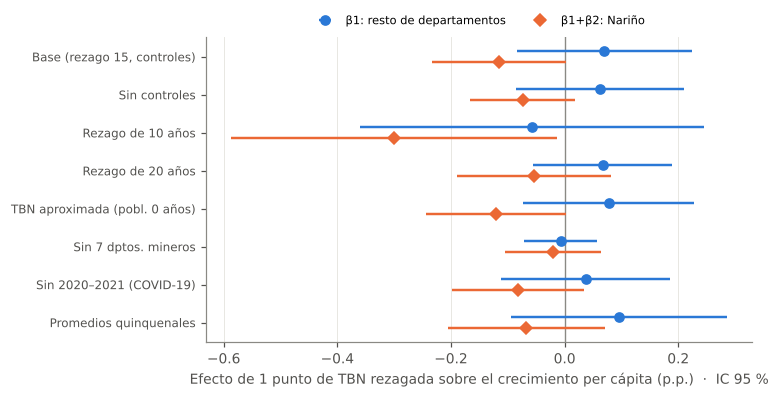

In [15]:
def efectos(df, x_tbn="tbn_l15", controles=CONTROLES):
    d = df.copy()
    d["inter"] = d[x_tbn] * d.narino
    r = estimar(d, "g", [x_tbn, "inter"] + controles)
    b1, s1 = r.params[x_tbn], r.std_errors[x_tbn]
    V = r.cov.loc[[x_tbn, "inter"], [x_tbn, "inter"]].values
    return b1, s1, b1 + r.params["inter"], np.sqrt(V.sum()), int(r.nobs)

mineros = est.groupby("dp").minas_sh.mean().loc[lambda s: s >= 15].index
quinq = est.assign(periodo=pd.cut(est.anio, [2005, 2010, 2015, 2020, 2024], labels=[2010, 2015, 2020, 2024]).astype(int))
quinq = quinq.groupby(["dp", "periodo"], as_index=False)[["g", "tbn_l15", "narino"] + CONTROLES].mean().rename(columns={"periodo": "anio"})
ESPEC = {
    "Base (rezago 15, controles)": efectos(est),
    "Sin controles": efectos(est, controles=[]),
    "Rezago de 10 años": efectos(est, "tbn_l10"),
    "Rezago de 20 años": efectos(est, "tbn_l20"),
    "TBN aproximada (pobl. 0 años)": efectos(est, "tbn_p0_l15"),
    f"Sin {len(mineros)} dptos. mineros": efectos(est[~est.dp.isin(mineros)]),
    "Sin 2020–2021 (COVID-19)": efectos(est[~est.anio.isin([2020, 2021])]),
    "Promedios quinquenales": efectos(quinq),
}
rob = pd.DataFrame(ESPEC, index=["β1 (resto)", "ee β1", "β1+β2 (Nariño)", "ee Nariño", "N"]).T
guardar_tabla(rob.round(3), "Tabla_7b_robustez")
display(rob.round(3))

fig, ax = plt.subplots(figsize=(6.4, 3.6))
yy = np.arange(len(rob))[::-1]
ax.axvline(0, color="#8a8984", lw=0.9)
ax.errorbar(rob["β1 (resto)"], yy + 0.15, xerr=1.96 * rob["ee β1"], fmt="o", color=C_COL, ms=6, capsize=0, lw=1.6,
            label="β1: resto de departamentos")
ax.errorbar(rob["β1+β2 (Nariño)"], yy - 0.15, xerr=1.96 * rob["ee Nariño"], fmt="D", color=C_NAR, ms=5.5, capsize=0, lw=1.6,
            label="β1+β2: Nariño")
ax.set_yticks(yy, rob.index, fontsize=7.8)
ax.set_xlabel("Efecto de 1 punto de TBN rezagada sobre el crecimiento per cápita (p.p.)  ·  IC 95 %")
ax.legend(fontsize=7.5, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
ax.grid(axis="y", visible=False)
guardar_fig(fig, "Figura_6_robustez")

### Figura 7. Inferencia por aleatorización: interacción placebo para cada departamento

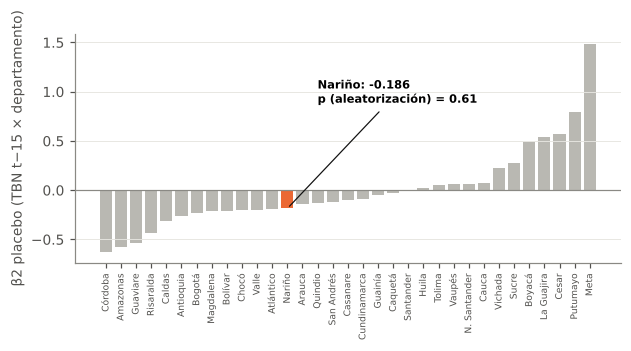

In [16]:
fig, ax = plt.subplots(figsize=(6.4, 2.7))
colores = [C_NAR if dp == "52" else C_GRIS for dp in placebo.index]
ax.bar(range(len(placebo)), placebo.values, color=colores, width=0.8)
ax.axhline(0, color="#8a8984", lw=0.8)
i_n = list(placebo.index).index("52")
ax.annotate(f"Nariño: {b2_nar:.3f}\np (aleatorización) = {p_ri:.2f}", (i_n, b2_nar),
            xytext=(i_n - 12 if i_n > 16 else i_n + 2, placebo.max() * 0.6), fontsize=7.5, fontweight="bold",
            arrowprops=dict(arrowstyle="-", color="#111111", lw=0.8))
CORTO = {"76": "Valle", "54": "N. Santander", "88": "San Andrés", "11": "Bogotá", "25": "Cundinamarca"}
ax.set_xticks(range(len(placebo)), [CORTO.get(d, NOMBRE[d]) for d in placebo.index], rotation=90, fontsize=6)
ax.set_ylabel("β2 placebo (TBN t−15 × departamento)")
ax.grid(axis="x", visible=False)
guardar_fig(fig, "Figura_7_placebo")

## 7. Serie de tiempo para Nariño: ARDL (objetivo 3; H2)
$$TGP_t = c + \phi\,TGP_{t-1} + \theta_0\,TBN_{t-15} + \theta_1\,TBN_{t-16} + \delta\,D_{2020} + u_t$$
Con 18 observaciones anuales (2007–2024) se restringe el orden máximo a 1 y se selecciona por AIC. Se reportan raíces unitarias (ADF, KPSS, Zivot-Andrews), la prueba de límites de Pesaran, Shin y Smith (2001) y diagnósticos de residuos.

In [17]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.ardl import ARDL, UECM, ardl_select_order
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, het_breuschpagan, linear_reset
from statsmodels.stats.stattools import jarque_bera
from arch.unitroot import ZivotAndrews

ts = panel[(panel.dp == "52") & panel.anio.between(2007, 2024)].set_index("anio")[["tgp", "to", "tbn_l15", "g"]]
ts.index = pd.PeriodIndex(ts.index, freq="Y")
D2020 = pd.DataFrame({"D2020": (ts.index.year == 2020).astype(float)}, index=ts.index)

def raiz_unitaria(s, nombre, tendencia="c"):
    s = s.dropna()
    adf = adfuller(s, maxlag=1, regression=tendencia, autolag=None)
    kp = kpss(s, regression=tendencia, nlags=1)
    try:
        za = ZivotAndrews(s.values, lags=0, trend="c", trim=0.15)
        za_s, za_p, za_q = za.stat, za.pvalue, ts.index.year[min(len(s) - 1, int(np.argmin(za._all_stats[~np.isnan(za._all_stats)])) + int(0.15 * len(s)))]
    except Exception:
        za_s, za_p, za_q = np.nan, np.nan, np.nan
    return (nombre, adf[0], adf[1], kp[0], kp[1], za_s, za_p)

raices = pd.DataFrame([
    raiz_unitaria(ts.tgp, "TGP (nivel)"), raiz_unitaria(ts.tgp.diff(), "ΔTGP"),
    raiz_unitaria(ts.tbn_l15, "TBN t−15 (nivel)", "ct"), raiz_unitaria(ts.tbn_l15.diff(), "ΔTBN t−15"),
    raiz_unitaria(ts.g, "g (nivel)"),
], columns=["Serie", "ADF", "p ADF", "KPSS", "p KPSS", "Zivot-Andrews", "p ZA"]).set_index("Serie")
display(raices.round(3))

sel = ardl_select_order(ts.tgp, 1, ts[["tbn_l15"]], 1, trend="c", fixed=D2020, ic="aic")
p_aic = max(sel.ar_lags) if sel.ar_lags else 0
q_aic = max(sel.dl_lags.get("tbn_l15", [0]) or [0]) if sel.dl_lags else 0
orden_aic = (p_aic, q_aic)
modelo_ardl = ARDL(ts.tgp, 1, ts[["tbn_l15"]], 1, trend="c", fixed=D2020)
res_ardl = modelo_ardl.fit()
uecm = UECM(ts.tgp, 1, ts[["tbn_l15"]], 1, trend="c", fixed=D2020).fit()
limites = uecm.bounds_test(case=3)

# Réplica por MCO del mismo ARDL(1,1) para diagnósticos y CUSUM
dd = pd.DataFrame({"tgp": ts.tgp, "tgp_l1": ts.tgp.shift(1), "x": ts.tbn_l15, "x_l1": ts.tbn_l15.shift(1), "D2020": D2020.D2020}).dropna()
Xo = sm.add_constant(dd[["tgp_l1", "x", "x_l1", "D2020"]])
ols = sm.OLS(dd.tgp, Xo).fit()
phi, t0, t1 = ols.params["tgp_l1"], ols.params["x"], ols.params["x_l1"]
lr = (t0 + t1) / (1 - phi)
grad = np.array([0, (t0 + t1) / (1 - phi) ** 2, 1 / (1 - phi), 1 / (1 - phi), 0])
lr_se = np.sqrt(grad @ ols.cov_params().values @ grad)
bg = acorr_breusch_godfrey(ols, nlags=1)
jb = jarque_bera(ols.resid)
bp = het_breuschpagan(ols.resid, Xo)
reset = linear_reset(ols, power=2, use_f=True)

tabla8 = pd.concat([raices.round(3), pd.DataFrame(index=[""])])
resumen_ardl = pd.DataFrame([
    ("Orden elegido por AIC (p, q)", f"({orden_aic[0]}, {orden_aic[1]})", ""),
    ("φ: TGP (t−1)", f"{phi:.3f}{estrellas(ols.pvalues['tgp_l1'])}", f"({ols.bse['tgp_l1']:.3f})"),
    ("θ0: TBN (t−15)", f"{t0:.3f}{estrellas(ols.pvalues['x'])}", f"({ols.bse['x']:.3f})"),
    ("θ1: TBN (t−16)", f"{t1:.3f}{estrellas(ols.pvalues['x_l1'])}", f"({ols.bse['x_l1']:.3f})"),
    ("δ: Dummy 2020", f"{ols.params['D2020']:.3f}{estrellas(ols.pvalues['D2020'])}", f"({ols.bse['D2020']:.3f})"),
    ("Multiplicador de largo plazo (θ0+θ1)/(1−φ)", f"{lr:.3f}{estrellas(2 * stats.norm.sf(abs(lr / lr_se)))}", f"({lr_se:.3f})"),
    ("Prueba de límites PSS (F, caso 3)", f"{limites.statistic:.3f}", f"p asintótico I(0) = {limites.pvalue['lower']:.3f} · I(1) = {limites.pvalue['upper']:.3f}"),
    ("Breusch-Godfrey AR(1)", f"{bg[0]:.3f}", f"p = {bg[1]:.3f}"),
    ("Jarque-Bera (normalidad)", f"{jb[0]:.3f}", f"p = {jb[1]:.3f}"),
    ("Breusch-Pagan (heterocedasticidad)", f"{bp[0]:.3f}", f"p = {bp[1]:.3f}"),
    ("RESET de Ramsey", f"{float(reset.fvalue):.3f}", f"p = {float(reset.pvalue):.3f}"),
    ("R² / observaciones", f"{ols.rsquared:.3f}", f"{int(ols.nobs)}"),
], columns=["Concepto", "Valor", "Detalle"]).set_index("Concepto")
guardar_tabla(raices.round(3), "Tabla_8a_raices_unitarias")
guardar_tabla(resumen_ardl, "Tabla_8b_ardl")
display(resumen_ardl)

,ADF,p ADF,KPSS,p KPSS,Zivot-Andrews,p ZA
Serie,,,,,,
TGP (nivel),-5.108,0.000,0.418,0.069,-3.463,0.703
ΔTGP,-2.795,0.059,0.239,0.100,-5.345,0.008
TBN t−15 (nivel),0.619,0.997,0.133,0.075,-3.617,0.603
ΔTBN t−15,-0.601,0.871,0.235,0.100,-4.879,0.042
g (nivel),-2.797,0.059,0.107,0.100,-5.736,0.002


,Valor,Detalle
Concepto,,
"Orden elegido por AIC (p, q)","(1, 0)",
φ: TGP (t−1),0.482**,(0.203)
θ0: TBN (t−15),-3.379,(4.322)
θ1: TBN (t−16),3.172,(4.191)
δ: Dummy 2020,-4.924**,(2.070)
Multiplicador de largo plazo (θ0+θ1)/(1−φ),-0.399,(0.365)
"Prueba de límites PSS (F, caso 3)",2.920,p asintótico I(0) = 0.131 · I(1) = 0.285
Breusch-Godfrey AR(1),0.045,p = 0.832
Jarque-Bera (normalidad),1.471,p = 0.479


### Figura 8. ARDL de Nariño: ajuste y estabilidad (CUSUM)

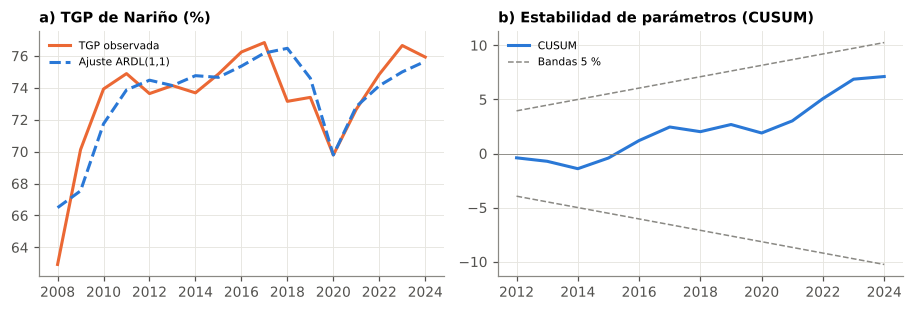

In [18]:
def cusum_recursivo(y, X):
    """Residuos recursivos (Brown, Durbin y Evans, 1975) y su suma acumulada normalizada.
    Se usa la pseudo-inversa porque la dummy de 2020 es cero en las primeras submuestras."""
    y, X = np.asarray(y, float), np.asarray(X, float)
    k = np.linalg.matrix_rank(X[:, :-1])          # regresores sin la dummy
    w = []
    for t in range(k, len(y)):
        Xi, yi = X[:t], y[:t]
        b = np.linalg.pinv(Xi) @ yi
        f = 1 + X[t] @ np.linalg.pinv(Xi.T @ Xi) @ X[t]
        w.append((y[t] - X[t] @ b) / np.sqrt(f))
    w = np.array(w)
    cus = np.cumsum(w) / w.std(ddof=1)
    n_r = len(w)
    j = np.arange(1, n_r + 1)
    banda = 0.948 * (np.sqrt(n_r) + 2 * j / np.sqrt(n_r))
    return cus, banda, k

cus, banda, k_par = cusum_recursivo(dd.tgp, Xo)
anios = dd.index.year
x_cus = anios[k_par:]
fig, ejes = plt.subplots(1, 2, figsize=(8.4, 2.9))
ax = ejes[0]
ax.plot(anios, dd.tgp, color=C_NAR, label="TGP observada")
ax.plot(anios, ols.fittedvalues, color=C_COL, ls="--", label="Ajuste ARDL(1,1)")
ax.set_title("a) TGP de Nariño (%)")
ax.legend(fontsize=7)
ax = ejes[1]
ax.plot(x_cus, cus, color=C_COL, label="CUSUM")
ax.plot(x_cus, banda, color="#8a8984", ls="--", lw=1, label="Bandas 5 %")
ax.plot(x_cus, -banda, color="#8a8984", ls="--", lw=1)
ax.axhline(0, color="#8a8984", lw=0.6)
ax.set_title("b) Estabilidad de parámetros (CUSUM)")
ax.legend(fontsize=7)
fig.tight_layout()
guardar_fig(fig, "Figura_8_ardl")

## 8. Interpretación económica
Dos lecturas complementarias:
* **Entre departamentos (largo plazo, columna 8)**: cuánto crecimiento anual se asocia con la caída de la natalidad de Nariño y si Nariño creció por encima o por debajo de lo que predice su transición demográfica (residuo).
* **Dentro de cada departamento (columna 3)**: traducción de la caída año a año de la TBN rezagada a puntos de crecimiento, con el efecto del resto del país (β1) y con el de Nariño (β1+β2).

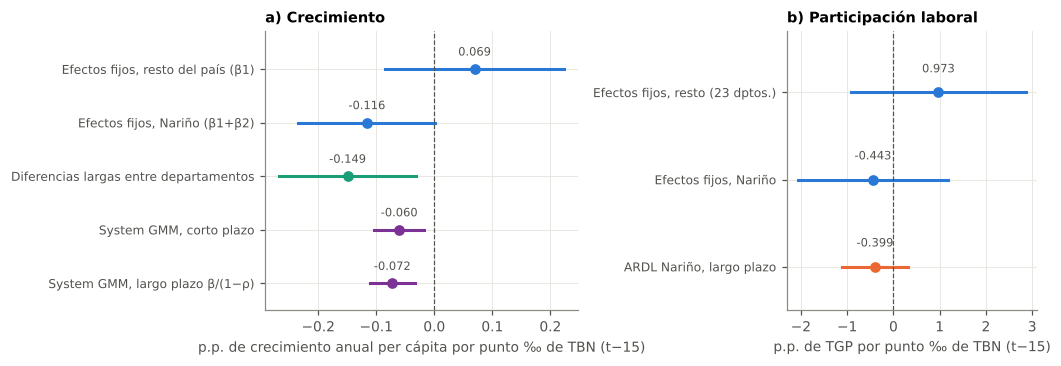

,valor
beta1,0.069
beta2,-0.186
beta_nar,-0.116
p_beta1_cluster,0.377
p_beta2_cluster,0.046
...,...
ee_tgp_nar,0.823
ee_tgp,0.965
p_tgp,0.314
ee_beta1,0.079


Entre departamentos: cada punto por mil de caída de la TBN (1991–2009) se asocia con 0.15 p.p. más de crecimiento anual per cápita en 2006–2024 (p = 0.013).
Nariño redujo su TBN en 8.9 puntos: eso predice +1.33 p.p. anuales (el departamento promedio: +1.09). Nariño creció +0.64 p.p. por encima de lo predicho (percentil 79 de los residuos).
Dentro de cada departamento: efecto del resto β1 = 0.069 (p bootstrap = 0.46); efecto de Nariño β1+β2 = -0.116; la diferencia no es atípica frente a los placebos (p = 0.61).


3861

In [19]:
r3 = MODELOS["(3) g"]
b1, b2 = r3.params["tbn_l15"], r3.params["tbn_l15_x_nar"]
nar = est[est.dp == "52"].set_index("anio")
delta = nar.tbn_l15 - nar.tbn_l15.loc[ANIO_INI]
contrib_nal = (b1 * delta).sum()
contrib_nar = ((b1 + b2) * delta).sum()
g_obs = nar.g.sum()
b_lp = r_largo.params["d_tbn"]
pred_lp_nar = b_lp * d_tbn["52"]
pred_lp_media = b_lp * d_tbn.drop("52").mean()
CLAVE = {
    "beta1": b1, "beta2": b2, "beta_nar": b1 + b2, "p_beta1_cluster": r3.pvalues["tbn_l15"],
    "p_beta2_cluster": r3.pvalues["tbn_l15_x_nar"], "p_beta1_wild": p_wb, "p_beta2_RI": p_ri,
    "delta_tbn_nar": float(delta.iloc[-1]), "delta_tbn_media_resto": float(d_tbn.drop("52").mean()),
    "efecto_anual_2024_nal": b1 * delta.iloc[-1], "efecto_anual_2024_nar": (b1 + b2) * delta.iloc[-1],
    "acumulado_nal": contrib_nal, "acumulado_nar": contrib_nar, "g_acumulado_observado": g_obs,
    "g_media_nar": nar.g.mean(),
    "beta_largo_plazo": b_lp, "p_largo_plazo": r_largo.pvalues["d_tbn"], "r2_largo_plazo": r_largo.rsquared,
    "pred_lp_nar_pp_anual": pred_lp_nar, "pred_lp_media_resto": pred_lp_media,
    "resid_nar_largo": resid_nar, "pct_resid_nar": pct_resid_nar,
    "beta_lp_convergencia": r_largo_conv.params["d_tbn"], "p_lp_convergencia": r_largo_conv.pvalues["d_tbn"],
    "beta_ln_y2005": r_largo_conv.params["ln_y2005"], "p_ln_y2005": r_largo_conv.pvalues["ln_y2005"],
    "pendiente_simple": pend.params.iloc[1], "p_pendiente_simple": pend.pvalues.iloc[1],
    "pendiente_sin_mineros": pend_sm.params.iloc[1], "p_pendiente_sin_mineros": pend_sm.pvalues.iloc[1],
    "beta_tgp": MODELOS["(6) TGP · H2"].params["tbn_l15"], "beta_tgp_nar": MODELOS["(6) TGP · H2"].params[["tbn_l15", "tbn_l15_x_nar"]].sum(),
    "beta_inf": MODELOS["(4) g · H3"].params["tbn_l15_x_inf"], "p_inf": MODELOS["(4) g · H3"].pvalues["tbn_l15_x_inf"],
    "beta_pet": MODELOS["(5) g · PET"].params["d_ln_pet_sh"], "p_pet": MODELOS["(5) g · PET"].pvalues["d_ln_pet_sh"],
    "ardl_largo_plazo": lr, "ardl_lr_se": lr_se, "bounds_F": limites.statistic,
    "bounds_p_I0": limites.pvalue["lower"], "bounds_p_I1": limites.pvalue["upper"],
    "ardl_phi": phi, "ardl_d2020": ols.params["D2020"],
}
# Cifras descriptivas citadas en el texto del PDF
dn = demo[demo.dp == "52"].set_index("anio")
nl = geih[geih.dp == "52"].set_index("anio")
cruce = dn.loc[2025:2050].query("dep_vej >= dep_juv").index
DESC = {"tgf_nar_1985": dn.tgf[1985], "tgf_nar_2014": dn.tgf[2014], "tgf_nar_2017": dn.tgf[2017],
        "tbn_nar_1991": dn.tbn[1991], "tbn_nar_2009": dn.tbn[2009],
        "anio_reemplazo_nar": int(dn.loc[1985:2017].query("tgf < 2.1").index.min()),
        "depjuv_nar_1985": dn.dep_juv[1985], "depjuv_nar_2024": dn.dep_juv[2024],
        "anio_cruce_dep": int(cruce.min()) if len(cruce) else 0,
        "pet_nar_2005": dn.pet_sh[2005], "pet_nar_2024": dn.pet_sh[2024], "pet_nar_2035": dn.pet_sh[2035],
        "tgp_nar_2007": nl.tgp[2007], "tgp_nar_2024": nl.tgp[2024], "to_nar_2007": nl.to[2007], "to_nar_2024": nl.to[2024],
        "tgp_agg_2024": agg.tgp[2024], "to_agg_2024": agg.to[2024], "td_nar_max": nl.td.loc[:2024].max(),
        "td_nar_max_anio": int(nl.td.loc[:2024].idxmax()), "td_nar_2024": nl.td[2024], "inf_23_media": inf_23.mean()}
CLAVE.update(DESC)
CLAVE.update(GMM_CLAVE)

# --- Figura 9. Confrontación de los métodos sobre el mismo parámetro ---
# a) Crecimiento: p.p. de crecimiento anual per cápita por cada punto por mil de TBN (t−15)
# b) Participación laboral: p.p. de TGP por cada punto por mil de TBN (t−15)
V9 = GMM["(9) GMM anual"]["V"].loc[["L1.g", "tbn_l15"], ["L1.g", "tbn_l15"]].values
rho9, b9 = GMM_CLAVE["gmm_rho"], GMM_CLAVE["gmm_tbn"]
grad9 = np.array([b9 / (1 - rho9) ** 2, 1 / (1 - rho9)])
V3 = r3.cov.loc[["tbn_l15", "tbn_l15_x_nar"], ["tbn_l15", "tbn_l15_x_nar"]].values
r6 = MODELOS["(6) TGP · H2"]
V6 = r6.cov.loc[["tbn_l15", "tbn_l15_x_nar"], ["tbn_l15", "tbn_l15_x_nar"]].values
COMPARA = pd.DataFrame([
    ("a) Crecimiento", "Efectos fijos, resto del país (β1)", "Panel EF", b1, r3.std_errors["tbn_l15"]),
    ("a) Crecimiento", "Efectos fijos, Nariño (β1+β2)", "Panel EF", b1 + b2, np.sqrt(V3.sum())),
    ("a) Crecimiento", "Diferencias largas entre departamentos", "Diferencias largas", b_lp, r_largo.bse["d_tbn"]),
    ("a) Crecimiento", "System GMM, corto plazo", "System GMM", b9, GMM_CLAVE["gmm_tbn_ee"]),
    ("a) Crecimiento", "System GMM, largo plazo β/(1−ρ)", "System GMM", GMM_CLAVE["gmm_lp"], float(np.sqrt(grad9 @ V9 @ grad9))),
    ("b) Participación laboral", "Efectos fijos, resto (23 dptos.)", "Panel EF", r6.params["tbn_l15"], r6.std_errors["tbn_l15"]),
    ("b) Participación laboral", "Efectos fijos, Nariño", "Panel EF", r6.params[["tbn_l15", "tbn_l15_x_nar"]].sum(), np.sqrt(V6.sum())),
    ("b) Participación laboral", "ARDL Nariño, largo plazo", "ARDL", lr, lr_se),
], columns=["Resultado", "Estimador", "Método", "coef", "ee"])
COMPARA["li"], COMPARA["ls"] = COMPARA.coef - 1.96 * COMPARA.ee, COMPARA.coef + 1.96 * COMPARA.ee
guardar_tabla(COMPARA.set_index(["Resultado", "Estimador"]).round(3), "Tabla_9_confrontacion")
COLORES_M = {"Panel EF": C_COL, "Diferencias largas": "#1b9e77", "System GMM": "#7b3294", "ARDL": C_NAR}
fig, ejes = plt.subplots(1, 2, figsize=(9.6, 3.4), gridspec_kw={"width_ratios": [1.25, 1]})
for ax, (res_, sub) in zip(ejes, COMPARA.groupby("Resultado", sort=True)):
    sub = sub.iloc[::-1].reset_index(drop=True)
    for k_, f_ in sub.iterrows():
        ax.plot([f_.li, f_.ls], [k_, k_], color=COLORES_M[f_["Método"]], lw=2)
        ax.plot(f_.coef, k_, "o", color=COLORES_M[f_["Método"]], ms=6)
        ax.text(f_.coef, k_ + 0.2, f"{f_.coef:.3f}", ha="center", va="bottom", fontsize=7.5, color=C_TXT)
    ax.axvline(0, color=C_TXT, lw=0.8, ls="--")
    ax.set_yticks(range(len(sub)))
    ax.set_yticklabels(sub.Estimador, fontsize=8)
    ax.set_ylim(-0.5, len(sub) - 0.3)
    ax.set_title(res_)
ejes[0].set_xlabel("p.p. de crecimiento anual per cápita por punto ‰ de TBN (t−15)")
ejes[1].set_xlabel("p.p. de TGP por punto ‰ de TBN (t−15)")
fig.tight_layout()
guardar_fig(fig, "Figura_9_confrontacion")
CLAVE.update({"gmm_lp_ee": float(np.sqrt(grad9 @ V9 @ grad9)), "ee_beta_nar": float(np.sqrt(V3.sum())),
              "ee_tgp_nar": float(np.sqrt(V6.sum())), "ee_tgp": float(r6.std_errors["tbn_l15"]), "p_tgp": float(r6.pvalues["tbn_l15"]),
              "ee_beta1": float(r3.std_errors["tbn_l15"]), "ee_largo_plazo": float(r_largo.bse["d_tbn"])})
interpretacion = pd.Series(CLAVE)
display(interpretacion.round(3).to_frame("valor"))
print(f"Entre departamentos: cada punto por mil de caída de la TBN (1991–2009) se asocia con {-b_lp:.2f} p.p. más de crecimiento "
      f"anual per cápita en 2006–2024 (p = {r_largo.pvalues['d_tbn']:.3f}).")
print(f"Nariño redujo su TBN en {-d_tbn['52']:.1f} puntos: eso predice {pred_lp_nar:+.2f} p.p. anuales "
      f"(el departamento promedio: {pred_lp_media:+.2f}). Nariño creció {resid_nar:+.2f} p.p. por encima de lo predicho "
      f"(percentil {pct_resid_nar:.0f} de los residuos).")
print(f"Dentro de cada departamento: efecto del resto β1 = {b1:.3f} (p bootstrap = {p_wb:.2f}); efecto de Nariño β1+β2 = {b1 + b2:.3f}; "
      f"la diferencia no es atípica frente a los placebos (p = {p_ri:.2f}).")
(BASE / "salidas" / "resultados_clave.json").write_text(
    json.dumps({k: (int(v) if isinstance(v, (int, np.integer)) else float(v)) for k, v in CLAVE.items()}, indent=2))

## 9. Exploración interactiva
Los controles se actualizan al cambiarlos. Si un panel no aparece en Colab, ejecute de nuevo la celda.
### 9.1 Series por departamento

In [20]:
import plotly.express as px
import plotly.graph_objects as go
import ipywidgets as widgets
from ipywidgets import interact
import plotly.io as pio
pio.renderers.default = "colab" if EN_COLAB else "notebook_connected"
if EN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

VARS_INT = {"Tasa bruta de natalidad (‰)": "tbn", "TBN aproximada, pobl. 0 años (‰)": "tbn_p0",
            "Tasa global de fecundidad": "tgf", "PET 15–64 (% población)": "pet_sh",
            "Dependencia juvenil": "dep_juv", "Dependencia de vejez": "dep_vej",
            "PIB real per cápita ($ de 2015)": "ypc", "Crecimiento PIB per cápita (%)": "g",
            "Tasa global de participación (%)": "tgp", "Tasa de ocupación (%)": "to", "Tasa de desocupación (%)": "td"}
serie_int = demo.merge(panel[["dp", "anio", "ypc", "g", "tgp", "to", "td"]], on=["dp", "anio"], how="left")
OPC_DPTOS = [("Colombia (total)", "00")] + sorted([(NOMBRE[k], k) for k in NOMBRE if k != "00"])

def ver_series(variable, departamentos):
    d = serie_int[serie_int.dp.isin(departamentos)].dropna(subset=[variable])
    nombre_var = next(k for k, v in VARS_INT.items() if v == variable)
    fig = px.line(d, x="anio", y=variable, color="depto", labels={"anio": "Año", variable: nombre_var, "depto": ""},
                  title=nombre_var, template="simple_white", height=420)
    fig.update_traces(line_width=2.5)
    fig.update_layout(hovermode="x unified")
    fig.show()

interact(ver_series,
         variable=widgets.Dropdown(options=VARS_INT, value="tbn", description="Variable"),
         departamentos=widgets.SelectMultiple(options=OPC_DPTOS, value=("52", "00"), rows=8,
                                              description="Dptos.", layout=widgets.Layout(width="320px")));

interactive(children=(Dropdown(description='Variable', options={'Tasa bruta de natalidad (‰)': 'tbn', 'TBN apr…

### 9.2 Mapa interactivo por año

In [21]:
GEO = json.loads((RAW / "mapa_departamentos.geojson").read_text(encoding="utf-8"))

def ver_mapa(variable, anio):
    d = serie_int[(serie_int.anio == anio) & (serie_int.dp != "00")].dropna(subset=[variable])
    nombre_var = next(k for k, v in VARS_INT.items() if v == variable)
    if d.empty:
        print(f"Sin datos de «{nombre_var}» para {anio}.")
        return
    fig = px.choropleth(d, geojson=GEO, locations="dp", featureidkey="properties.DPTO_CCDGO", color=variable,
                        hover_name="depto", color_continuous_scale="Blues", labels={variable: nombre_var},
                        title=f"{nombre_var}, {anio}", height=560)
    fig.update_geos(fitbounds="locations", visible=False)
    fig.show()

interact(ver_mapa, variable=widgets.Dropdown(options=VARS_INT, value="tbn", description="Variable"),
         anio=widgets.IntSlider(value=2005, min=1985, max=2050, step=1, description="Año", continuous_update=False));

interactive(children=(Dropdown(description='Variable', options={'Tasa bruta de natalidad (‰)': 'tbn', 'TBN apr…

### 9.3 Pirámide poblacional

In [22]:
def ver_piramide(dp, anio):
    p = piramide(dp, anio)
    grupos = [f"{g}–{g+4}" if g < 80 else "80+" for g in p.index]
    fig = go.Figure([go.Bar(y=grupos, x=-p["Hombres"], orientation="h", name="Hombres", marker_color=C_COL,
                            customdata=p["Hombres"], hovertemplate="%{y}: %{customdata:.2f}%<extra>Hombres</extra>"),
                     go.Bar(y=grupos, x=p["Mujeres"], orientation="h", name="Mujeres", marker_color=C_NAR,
                            hovertemplate="%{y}: %{x:.2f}%<extra>Mujeres</extra>")])
    fig.update_layout(barmode="overlay", bargap=0.08, template="simple_white", height=480,
                      title=f"{NOMBRE[dp]}, {anio} (% de la población)", xaxis=dict(tickvals=[-6, -3, 0, 3, 6], ticktext=["6", "3", "0", "3", "6"]))
    fig.show()

interact(ver_piramide, dp=widgets.Dropdown(options=OPC_DPTOS, value="52", description="Dpto."),
         anio=widgets.IntSlider(value=2024, min=1985, max=2050, description="Año", continuous_update=False));

interactive(children=(Dropdown(description='Dpto.', index=23, options=(('Colombia (total)', '00'), ('Amazonas'…

### 9.4 Re-estimar el panel en vivo
Cambie el rezago, los controles o la muestra; la tabla muestra β1 (resto del país) y β1+β2 (Nariño).

In [23]:
def reestimar(rezago, controles, excluir_mineros, excluir_covid):
    d = agrega_rezago(est, "tbn", rezago, "x_tbn")
    if excluir_mineros:
        d = d[~d.dp.isin(mineros)]
    if excluir_covid:
        d = d[~d.anio.isin([2020, 2021])]
    d["x_tbn_nar"] = d.x_tbn * d.narino
    r = estimar(d, "g", ["x_tbn", "x_tbn_nar"] + (CONTROLES if controles else []))
    V = r.cov.loc[["x_tbn", "x_tbn_nar"], ["x_tbn", "x_tbn_nar"]].values
    b_n, s_n = r.params["x_tbn"] + r.params["x_tbn_nar"], np.sqrt(V.sum())
    out = pd.DataFrame({"coeficiente": [r.params["x_tbn"], b_n], "error estándar": [r.std_errors["x_tbn"], s_n],
                        "valor p": [r.pvalues["x_tbn"], 2 * stats.norm.sf(abs(b_n / s_n))]},
                       index=[f"β1: TBN (t−{rezago}), resto del país", "β1+β2: Nariño"])
    display(out.round(3))
    print(f"Observaciones: {int(r.nobs)} · departamentos: {r.entity_info['total']:.0f} · R² within: {r.rsquared:.3f}")

interact(reestimar, rezago=widgets.IntSlider(value=15, min=10, max=20, description="Rezago", continuous_update=False),
         controles=widgets.Checkbox(value=True, description="Con controles"),
         excluir_mineros=widgets.Checkbox(value=False, description="Sin dptos. mineros"),
         excluir_covid=widgets.Checkbox(value=False, description="Sin 2020–2021"));

interactive(children=(IntSlider(value=15, continuous_update=False, description='Rezago', max=20, min=10), Chec…

### 9.5 Contexto internacional en vivo (API del Banco Mundial)
Consulta directa a `api.worldbank.org`. Colombia frente a América Latina y el Caribe, Ecuador, Perú y el mundo.

In [24]:
WB_IND = {"Tasa global de fecundidad": "SP.DYN.TFRT.IN", "Tasa bruta de natalidad (‰)": "SP.DYN.CBRT.IN",
          "Población 15–64 (% del total)": "SP.POP.1564.TO.ZS", "Crecimiento del PIB per cápita (%)": "NY.GDP.PCAP.KD.ZG"}
_cache_wb = {}

def banco_mundial(indicador, paises="COL;LCN;ECU;PER;WLD", desde=1985, hasta=2024):
    if indicador not in _cache_wb:
        url = f"https://api.worldbank.org/v2/country/{paises}/indicator/{indicador}?format=json&per_page=2000&date={desde}:{hasta}"
        r = requests.get(url, timeout=30)
        r.raise_for_status()
        _cache_wb[indicador] = pd.DataFrame([{"pais": x["country"]["value"], "anio": int(x["date"]), "valor": x["value"]}
                                             for x in r.json()[1]]).dropna()
    return _cache_wb[indicador]

def ver_wb(indicador):
    try:
        d = banco_mundial(indicador)
    except Exception as e:
        print("No fue posible consultar la API del Banco Mundial:", type(e).__name__)
        return
    nombre = next(k for k, v in WB_IND.items() if v == indicador)
    fig = px.line(d.sort_values("anio"), x="anio", y="valor", color="pais", template="simple_white", height=420,
                  labels={"anio": "Año", "valor": nombre, "pais": ""}, title=f"{nombre} — Banco Mundial (WDI)")
    fig.update_layout(hovermode="x unified")
    fig.show()

interact(ver_wb, indicador=widgets.Dropdown(options=WB_IND, value="SP.DYN.TFRT.IN", description="Indicador"));

interactive(children=(Dropdown(description='Indicador', options={'Tasa global de fecundidad': 'SP.DYN.TFRT.IN'…

## 10a. Datos abiertos para el observatorio
Se exportan en `salidas/datos/` las bases armonizadas que alimentan el observatorio estadístico del repositorio (`docs/`) y el sistema de consulta (RAG). Así el sitio web y el chatbot usan exactamente las mismas cifras del artículo.

In [25]:
DATOS = BASE / "salidas" / "datos"
DATOS.mkdir(parents=True, exist_ok=True)
cols_panel = ["dp", "depto", "anio", "pob", "ypc", "g", "tbn", "tgf", "pet_sh", "dep_juv", "dep_vej", "tgp", "to", "td", "agro_sh", "minas_sh"]
panel[panel.anio.between(2005, ANIO_FIN)][[c for c in cols_panel if c in panel.columns]].round(4).to_csv(DATOS / "panel_departamental.csv", index=False)
demo_exp = demo.copy()
demo_exp["depto"] = demo_exp.dp.map(NOMBRE)
demo_exp[["dp", "depto", "anio", "pob", "tbn", "tgf", "pet_sh", "dep_juv", "dep_vej"]].round(4).to_csv(DATOS / "demografia_1985_2050.csv", index=False)
informalidad.assign(depto=informalidad.dp.map(NOMBRE)).round(3).to_csv(DATOS / "informalidad_capitales.csv", index=False)
print({p.name: sum(1 for _ in open(p)) - 1 for p in DATOS.glob("*.csv")})

{'demografia_1985_2050.csv': 2244, 'informalidad_capitales.csv': 96, 'panel_departamental.csv': 660}


## 10b. Rastreador de fuentes y observatorio estadístico
**Rastreador de datos.** Revisa cada fuente oficial listada en `rastreador/fuentes.json` y deja constancia de su estado:
* archivos (DANE, FNC, GitHub): código HTTP, fecha de modificación, tamaño y huella SHA-256 del archivo publicado frente a la copia de `datos/raw/`;
* conjuntos de datos.gov.co: fecha de la última actualización según la API de metadatos;
* páginas índice: archivos de datos enlazados (detecta anexos nuevos);
* API del Banco Mundial: último año con dato.

Cada ejecución agrega una fila por fuente a `rastreador/registro.csv` (historial). «Versión nueva publicada» indica que conviene volver a ejecutar el notebook con `INTENTAR_DESCARGA = True`; «no accesible» indica que el servidor rechaza conexiones desde la nube (el DANE lo hace con Colab), y en ese caso el análisis usa la copia guardada.

**Observatorio estadístico.** El observatorio (`docs/`) se reconstruye con los resultados de esta ejecución y se abre dentro de Colab, debajo de la segunda celda. Tiene series, mapa, confrontación de métodos, estado de las fuentes y descargas. La misma página puede publicarse en GitHub Pages.

In [26]:
import subprocess, json, html as _html
from IPython.display import HTML
_r = subprocess.run([sys.executable, str(BASE / "rastreador" / "verificar_fuentes.py")], cwd=BASE, capture_output=True, text=True, timeout=900)
if _r.returncode != 0:
    print(_r.stderr[-1500:])
ESTADO_FUENTES = json.loads((BASE / "rastreador" / "estado_fuentes.json").read_text(encoding="utf-8"))
COLOR_ESTADO = {"versión nueva publicada": "#fdebdc", "sin cambios": "#e3f4ec", "sin cambios frente a la copia": "#e3f4ec", "primera revisión": "#e3f4ec"}
filas_html = "".join(
    f"<tr><td><a href='{f['url']}' target='_blank'>{_html.escape(f['nombre'])}</a></td><td>{_html.escape(f['entidad'])}</td><td>{f['tipo']}</td>"
    f"<td>{f.get('estado_http') or '—'}</td><td style='background:{COLOR_ESTADO.get(f['estado'], '#efeeea')}'>{f['estado']}</td>"
    f"<td>{f.get('ultima_modificacion') or f.get('ultimo_dato') or '—'}</td></tr>" for f in ESTADO_FUENTES["fuentes"])
display(HTML(f"<h4 style='font-family:sans-serif'>Estado de las fuentes · revisado {ESTADO_FUENTES['revisado']}</h4>"
             f"<table style='font-family:sans-serif;font-size:13px;border-collapse:collapse'><tr><th>Fuente</th><th>Entidad</th><th>Tipo</th>"
             f"<th>HTTP</th><th>Estado</th><th>Última modificación</th></tr>{filas_html}</table>"))
historial = pd.read_csv(BASE / "rastreador" / "registro.csv")
print(f"Historial: {len(historial)} registros de {historial.revisado.nunique()} revisiones (rastreador/registro.csv).")

Fuente,Entidad,Tipo,HTTP,Estado,Última modificación
"PIB departamental, base 2015 (total)",DANE,archivo,—,no accesible desde el servidor,—
PIB departamental por actividad,DANE,archivo,—,no accesible desde el servidor,—
Página de cuentas departamentales (nuevos anexos),DANE,pagina,—,no accesible desde el servidor,—
Proyecciones de población 2018–2050,DANE,archivo,—,no accesible desde el servidor,—
Retroproyecciones de población 2005–2017,DANE,archivo,—,no accesible desde el servidor,—
Estimaciones de fecundidad 1985–2017,DANE,archivo,—,no accesible desde el servidor,—
GEIH: mercado laboral por departamento,DANE,archivo,—,no accesible desde el servidor,—
GEIH: empleo informal por ciudad,DANE,archivo,—,no accesible desde el servidor,—
Límites departamentales MGN 2018,DANE vía GitHub,archivo,200,sin cambios frente a la copia,—
Banco Mundial: TGF de Colombia (SP.DYN.TFRT.IN),Banco Mundial,api,—,no accesible desde el servidor,—


Historial: 11 registros de 1 revisiones (rastreador/registro.csv).


In [27]:
import socket
subprocess.run([sys.executable, str(BASE / "observatorio" / "construir.py")], check=True)
PUERTO = 8765
with socket.socket() as _s:
    _libre = _s.connect_ex(("127.0.0.1", PUERTO)) != 0
if _libre:                                    # servidor local de la carpeta docs/ (se reutiliza si ya está activo)
    SERVIDOR = subprocess.Popen([sys.executable, "-m", "http.server", str(PUERTO), "-d", str(BASE / "docs")],
                                stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
if EN_COLAB:
    from google.colab import output as _out
    _out.serve_kernel_port_as_iframe(PUERTO, path="/index.html", height=950)
else:
    from IPython.display import IFrame
    display(IFrame(f"http://localhost:{PUERTO}/index.html", width="100%", height=950))
    print(f"Observatorio: http://localhost:{PUERTO}/index.html")

docs/datos.json: 149 KB


Observatorio: http://localhost:8765/index.html


## 10. Exportar resultados
Empaqueta `salidas/` (figuras y tablas numeradas como en el PDF) en `salidas.zip`; en Colab se descarga automáticamente.

In [28]:
ruta_zip = BASE / "salidas.zip"
with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted((BASE / "salidas").rglob("*")):
        if f.is_file():
            z.write(f, f.relative_to(BASE))
print("Archivos generados:")
for f in sorted((BASE / "salidas").rglob("*.*")):
    print("  ", f.relative_to(BASE))
if EN_COLAB:
    from google.colab import files
    files.download(str(ruta_zip))

Archivos generados:
   salidas/datos/demografia_1985_2050.csv
   salidas/datos/informalidad_capitales.csv
   salidas/datos/panel_departamental.csv
   salidas/figuras/Figura_1_mapas.png
   salidas/figuras/Figura_2_transicion.png
   salidas/figuras/Figura_3_piramides.png
   salidas/figuras/Figura_4_mercado_laboral.png
   salidas/figuras/Figura_5_dispersion.png
   salidas/figuras/Figura_6_robustez.png
   salidas/figuras/Figura_7_placebo.png
   salidas/figuras/Figura_8_ardl.png
   salidas/figuras/Figura_9_confrontacion.png
   salidas/figuras_en/Figura_1_mapas.png
   salidas/figuras_en/Figura_2_transicion.png
   salidas/figuras_en/Figura_3_piramides.png
   salidas/figuras_en/Figura_4_mercado_laboral.png
   salidas/figuras_en/Figura_5_dispersion.png
   salidas/figuras_en/Figura_6_robustez.png
   salidas/figuras_en/Figura_7_placebo.png
   salidas/figuras_en/Figura_8_ardl.png
   salidas/figuras_en/Figura_9_confrontacion.png
   salidas/resultados_clave.json
   salidas/tablas/Tabla_2_operacional